# What drives a country's CO₂ emissions? Explainable ML on World Bank ESG data

**Name: Keith Phang**

**Student ID: 25034227**

**NGDS Assignment 1: Explainable Machine Learning Modelling on a Real-World Dataset** (6FTC2177)



**Theme:** Societal challenges, climate change.

**In one sentence:** I build a leakage-safe ML pipeline that predicts a country's **CO₂ emissions per person** from environmental, social and governance indicators. I then use XAI (SHAP, PDP/ICE, ALE, permutation importance and LIME) to explain *which* national characteristics the model links to high emissions, and *why* it makes a given prediction.

**Contents**
1. Setup
2. Load the data (World Bank Data360, ESG database)
3. Problem definition and success criteria
4. Data understanding, data quality and leakage audit
5. Feature construction and train/test split (grouped by country)
6. Exploratory data analysis (EDA)
7. Principal Component Analysis (PCA)
8. Preprocessing pipeline
9. Baseline and model comparison (cross-validation)
10. Hyperparameter tuning
11. AutoML with FLAML
12. Final evaluation on the held-out test set
13. Explainable AI (SHAP, PDP/ICE, ALE, permutation importance, LIME)
14. Conclusions, limitations and next steps

## 1. Setup

The cell below installs the extra libraries when the notebook runs in **Google Colab**, because SHAP, LIME, FLAML and LightGBM are not all pre-installed there. When running locally, install them from `requirements.txt`.

All randomness is controlled by one seed (`SEED = 42`), so the notebook reproduces end to end. Every figure is also saved to `figures/` for the slides.

In [ ]:
import sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "shap", "lime", "flaml", "lightgbm"], check=True)
print("Running in Colab:", IN_COLAB)

Running in Colab: True


In [ ]:
import os, re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from scipy.stats import loguniform, randint, uniform, spearmanr

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

from lightgbm import LGBMRegressor
from flaml import AutoML
import shap
from lime.lime_tabular import LimeTabularExplainer

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50, "display.width", 160)

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

import sklearn, lightgbm, flaml
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| lightgbm", lightgbm.__version__,
      "| shap", shap.__version__, "| flaml", flaml.__version__)

pandas 2.2.3 | scikit-learn 1.6.1 | lightgbm 4.6.0 | shap 0.52.0 | flaml 2.7.0


## 2. Load the data

**Source:** World Bank **Data360**, *Environment, Social & Governance (ESG)* database (`WB_ESG`): https://data360.worldbank.org/en/dataset/WB_ESG

**Licence:** World Bank open data, Creative Commons Attribution 4.0 (CC BY 4.0).

**Raw format:** the CSV is in **long format**, with one row per *country × indicator × year* value (about 460,000 rows, 239 economies, 71 indicators, 1960–2023). An ML model needs one row per observation, so the loader below:

1. keeps the years **2000–2020** (earlier years are mostly empty);
2. **pivots** to one row per *country-year*, with one column per indicator;
3. removes the ~45 **aggregates** ("World", "High income", "Sub-Saharan Africa" …). These are sums or averages of countries, so keeping them would count the same data twice. Real countries are identified with the World Bank country API, where aggregates have region `NA`;
4. adds each country's **region** and **income group** (two categorical features);
5. keeps rows where the target (CO₂ per person) is present, and renames indicator codes to short readable names.

The result is cached in `data/` so that the 185 MB raw file is only processed once.

In [ ]:
RAW_URL    = "https://data360files.worldbank.org/data360-data/data/WB_ESG/WB_ESG.csv"
RAW_LOCAL  = "data/WB_ESG.csv"                       # used instead of the URL if you have downloaded it
CLEAN_FILE = "data/esg_country_year_2000_2020.csv"   # cached result of this cell
START_YEAR, END_YEAR = 2000, 2020
TARGET_CODE = "WB_ESG_EN_ATM_CO2E_PC"

# Short readable names for the 71 indicator codes (prefix WB_ESG_ removed)
SHORT_NAMES = {
    "EN_ATM_CO2E_PC": "co2_per_capita", "EN_ATM_METH_PC": "methane_pc", "EN_ATM_NOXE_PC": "nitrous_oxide_pc",
    "EN_CLC_GHGR_MT_CE": "lucf_net_emissions", "EN_CLC_CDDY_XD": "cooling_degree_days",
    "EN_CLC_HDDY_XD": "heating_degree_days", "EN_CLC_HEAT_XD": "heat_index_35_days",
    "EN_LND_LTMP_DC": "land_surface_temp", "EN_CLC_SPEI_XD": "drought_index_spei",
    "EN_ATM_PM25_MC_M3": "pm25_exposure", "EN_POP_DNST": "population_density",
    "EN_CLC_CSTP_ZS": "coastal_protection", "EN_MAM_THRD_NO": "threatened_mammals",
    "EN_H2O_BDYS_ZS": "good_water_quality_pct", "AG_LND_AGRI_ZS": "agricultural_land_pct",
    "AG_LND_FRST_ZS": "forest_area_pct", "AG_LND_FRLS_HA": "tree_cover_loss_ha",
    "AG_PRD_FOOD_XD": "food_production_index", "ER_H2O_FWST_ZS": "water_stress_pct",
    "ER_H2O_FWTL_ZS": "freshwater_withdrawal_pct", "ER_PTD_TOTL_ZS": "protected_areas_pct",
    "EG_FEC_RNEW_ZS": "renewable_energy_pct", "EG_ELC_RNEW_ZS": "renewable_electricity_pct",
    "EG_ELC_COAL_ZS": "coal_electricity_pct", "EG_ELC_ACCS_ZS": "electricity_access_pct",
    "EG_CFT_ACCS_ZS": "clean_cooking_access_pct", "EG_EGY_PRIM_PP_KD": "energy_intensity",
    "EG_USE_PCAP_KG_OE": "energy_use_per_capita", "EG_USE_COMM_FO_ZS": "fossil_fuel_energy_pct",
    "EG_IMP_CONS_ZS": "energy_imports_pct", "NY_GDP_MKTP_KD_ZG": "gdp_growth",
    "NV_AGR_TOTL_ZS": "agriculture_gdp_pct", "NY_ADJ_DFOR_GN_ZS": "forest_depletion_gni_pct",
    "NY_ADJ_DRES_GN_ZS": "resource_depletion_gni_pct", "SP_DYN_LE00_IN": "life_expectancy",
    "SP_POP_65UP_TO_ZS": "pop_65plus_pct", "SP_DYN_TFRT_IN": "fertility_rate",
    "SM_POP_NETM": "net_migration", "SH_DYN_MORT": "under5_mortality", "SH_STA_OWAD_ZS": "overweight_pct",
    "SN_ITK_DEFC_ZS": "undernourishment_pct", "SH_MED_BEDS_ZS": "hospital_beds_per_1000",
    "SH_STA_SMSS_ZS": "safe_sanitation_pct", "SH_H2O_SMDW_ZS": "safe_drinking_water_pct",
    "SH_DTH_COMM_ZS": "communicable_deaths_pct", "SP_UWT_TFRT": "unmet_contraception_pct",
    "SE_PRM_ENRR": "primary_enrolment_pct", "SE_ENR_PRSC_FM_ZS": "school_gender_parity",
    "SE_XPD_TOTL_GB_ZS": "education_spend_pct", "SE_ADT_LITR_ZS": "adult_literacy_pct",
    "SL_TLF_ACTI_ZS": "labour_force_participation", "SL_UEM_TOTL_ZS": "unemployment_pct",
    "SL_TLF_CACT_FM_ZS": "female_male_labour_ratio", "SL_TLF_0714_ZS": "child_employment_pct",
    "SI_POV_GINI": "gini_index", "SI_DST_FRST_20": "income_share_lowest20",
    "SI_POV_NAHC": "poverty_headcount_pct", "SI_SPR_PCAP_ZG": "consumption_growth_pct",
    "IT_NET_USER_ZS": "internet_users_pct", "IP_JRN_ARTC_SC": "journal_articles",
    "IP_PAT_RESD": "patent_applications", "GB_XPD_RSDV_GD_ZS": "rnd_spend_gdp_pct",
    "SG_GEN_PARL_ZS": "women_in_parliament_pct", "SD_ESR_PERF_XQ": "econ_social_rights_score",
    "IC_LGL_CRED_XQ": "legal_rights_index", "CC_EST": "control_of_corruption",
    "GE_EST": "government_effectiveness", "PV_EST": "political_stability", "RQ_EST": "regulatory_quality",
    "RL_EST": "rule_of_law", "VA_EST": "voice_accountability",
}

def short_name(code):
    key = code.replace("WB_ESG_", "")
    return SHORT_NAMES.get(key, key.lower())

def build_dataset():
    src = RAW_LOCAL if os.path.exists(RAW_LOCAL) else RAW_URL
    print("Reading raw long-format file from:", src)
    raw = pd.read_csv(src, usecols=["REF_AREA", "INDICATOR", "INDICATOR_LABEL", "UNIT_MEASURE_LABEL",
                                    "TIME_PERIOD", "OBS_VALUE"], low_memory=False)
    print("Raw (long) shape:", raw.shape)
    raw = raw[raw["TIME_PERIOD"].between(START_YEAR, END_YEAR)]

    # 1) long -> wide: one row per country-year, one column per indicator
    wide = (raw.pivot_table(index=["REF_AREA", "TIME_PERIOD"], columns="INDICATOR",
                            values="OBS_VALUE", aggfunc="first").reset_index())
    wide.columns.name = None

    # 2) keep real countries only, and add region / income group
    resp = requests.get("https://api.worldbank.org/v2/country",
                        params={"format": "json", "per_page": 400}, timeout=60)
    countries = pd.DataFrame([{"REF_AREA": c["id"], "country": c["name"],
                               "region": c["region"]["value"].strip(),
                               "income_group": c["incomeLevel"]["value"].strip()}
                              for c in resp.json()[1] if c["region"]["id"] != "NA"])
    wide = wide.merge(countries, on="REF_AREA", how="inner")

    # 3) keep rows with a target value, readable names
    wide = wide[wide[TARGET_CODE].notna()]
    wide = wide.rename(columns={c: short_name(c) for c in wide.columns if c.startswith("WB_ESG_")})
    wide = wide.rename(columns={"REF_AREA": "country_code", "TIME_PERIOD": "year"})
    id_cols = ["country_code", "country", "region", "income_group", "year"]
    feats = sorted(c for c in wide.columns if c not in id_cols + ["co2_per_capita"])
    wide = wide[id_cols + feats + ["co2_per_capita"]].sort_values(["country_code", "year"])

    # data dictionary (description and unit of each column)
    labels = raw.drop_duplicates("INDICATOR").set_index("INDICATOR")
    dictionary = pd.DataFrame({"column": [short_name(c) for c in labels.index],
                               "indicator_code": labels.index,
                               "description": labels["INDICATOR_LABEL"].values,
                               "unit": labels["UNIT_MEASURE_LABEL"].values})
    dictionary.to_csv("data/esg_data_dictionary.csv", index=False)
    return wide.reset_index(drop=True)

if os.path.exists(CLEAN_FILE):
    df = pd.read_csv(CLEAN_FILE)
    print("Loaded cached file:", CLEAN_FILE)
else:
    t0 = time.perf_counter()
    df = build_dataset()
    df.to_csv(CLEAN_FILE, index=False)
    print(f"Built and cached in {time.perf_counter() - t0:.0f}s")

print(f"Shape: {df.shape[0]:,} country-years x {df.shape[1]} columns | "
      f"{df['country_code'].nunique()} countries | years {df['year'].min()}-{df['year'].max()}")
df.head()

Reading raw long-format file from: https://data360files.worldbank.org/data360-data/data/WB_ESG/WB_ESG.csv
Raw (long) shape: (461719, 6)
Built and cached in 12s
Shape: 4,011 country-years x 76 columns | 191 countries | years 2000-2020


,country_code,country,region,income_group,year,adult_literacy_pct,agricultural_land_pct,agriculture_gdp_pct,child_employment_pct,clean_cooking_access_pct,coal_electricity_pct,coastal_protection,communicable_deaths_pct,consumption_growth_pct,control_of_corruption,cooling_degree_days,drought_index_spei,econ_social_rights_score,education_spend_pct,electricity_access_pct,energy_imports_pct,energy_intensity,energy_use_per_capita,female_male_labour_ratio,fertility_rate,...,political_stability,pop_65plus_pct,population_density,poverty_headcount_pct,primary_enrolment_pct,protected_areas_pct,regulatory_quality,renewable_electricity_pct,renewable_energy_pct,resource_depletion_gni_pct,rnd_spend_gdp_pct,rule_of_law,safe_drinking_water_pct,safe_sanitation_pct,school_gender_parity,threatened_mammals,tree_cover_loss_ha,under5_mortality,undernourishment_pct,unemployment_pct,unmet_contraception_pct,voice_accountability,water_stress_pct,women_in_parliament_pct,co2_per_capita
0,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2000,NaN,57.945817,NaN,NaN,5.5,0.0,NaN,59.81465,NaN,-1.271724,1906.77,-1.598542,NaN,NaN,4.4,NaN,1.50,NaN,17.916255,7.566,...,-2.438969,2.261970,30.863847,NaN,22.162991,NaN,-2.080253,93.537318,45.0,NaN,NaN,-1.780661,11.093326,NaN,NaN,NaN,NaN,131.7,NaN,7.935,NaN,-2.031417,54.757019,NaN,0.053557
1,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2001,NaN,57.947350,NaN,NaN,6.6,0.0,NaN,NaN,NaN,NaN,1998.93,-2.002626,NaN,NaN,9.3,NaN,1.50,NaN,17.802784,7.453,...,NaN,2.261948,31.099929,NaN,22.908590,NaN,NaN,93.537318,45.6,NaN,NaN,NaN,11.105221,NaN,0.00000,NaN,NaN,127.4,46.0,7.953,NaN,NaN,54.757019,NaN,0.053669
2,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2002,NaN,57.939684,38.627892,NaN,7.7,0.0,NaN,NaN,NaN,-1.251137,1873.43,-0.580704,NaN,NaN,14.1,NaN,1.40,NaN,17.762103,7.320,...,-2.035034,2.263974,32.776961,NaN,75.959747,NaN,-1.811546,93.537450,37.8,NaN,NaN,-1.673473,12.007733,NaN,NaN,NaN,179.0,123.1,43.7,7.930,NaN,-1.433421,54.757019,NaN,0.065629
3,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2003,NaN,58.083805,37.418855,NaN,9.0,0.0,NaN,NaN,NaN,-1.344180,1776.66,0.604205,NaN,NaN,19.0,NaN,1.39,NaN,17.785639,7.174,...,-2.198372,2.266753,34.854344,NaN,96.553680,NaN,-1.463108,80.630860,36.7,NaN,NaN,-1.558294,12.909922,NaN,0.54426,NaN,244.0,118.7,38.6,7.880,NaN,-1.177571,54.757019,NaN,0.072723
4,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2004,NaN,58.151266,29.721067,NaN,10.5,0.0,NaN,NaN,NaN,-1.350647,1783.05,-0.711262,NaN,NaN,23.8,NaN,1.21,NaN,17.874372,7.018,...,-2.295682,2.268647,36.123230,NaN,106.252663,NaN,-1.511549,62.864936,44.2,NaN,NaN,-1.693925,13.818684,NaN,0.40582,NaN,201.0,114.2,35.9,7.899,NaN,-1.203034,54.757019,NaN,0.054850


The data is now in the shape a model needs: **one row per country per year**. Region and income group are categorical; all indicator columns are numeric.

The data dictionary (`data/esg_data_dictionary.csv`) records the description and unit of every column, so that every feature name used later can be traced back to its World Bank definition.

## 3. Problem definition and success criteria

**Why this matters.** CO₂ from fossil fuels is the main driver of climate change. Emissions per person differ more than 100-fold between countries. Understanding *which* national characteristics go with high emissions (energy mix, energy use, wealth, climate, governance) helps policymakers see where the biggest reductions are possible. This links directly to learning outcome 2: the relevance of data science to societal threats such as climate change.

**ML task:** supervised **regression**.

**What exactly the model predicts.** The model estimates a country's CO₂ per person **for a year that has already been observed**, using that country's other indicators for the same year. It is tested on **countries it has never seen**. It is therefore a **cross-sectional estimation** task, **not a forecast** of future emissions. Realistic uses are:

1. **cross-checking or gap-filling** national estimates for countries with weak emissions statistics;
2. **benchmarking**, i.e. flagging countries whose reported emissions are far above or below what their energy, development and economic profile would suggest.

Forecasting future years would need a different design (training on earlier years and testing on later ones), and is out of scope.

- **Unit of observation:** one country in one year (2000–2020).
- **Target:** `co2_per_capita`, CO₂ emissions in **tonnes per person per year**.
- **Inputs:** about 70 World Bank indicators (energy, environment, health, demography, economy, governance), plus region, income group and year.

**Modelling the target on a log scale.** CO₂ per person is very right-skewed (most countries emit under 5 t, a few Gulf states emit over 30 t). I therefore model `log1p(co2_per_capita)`. On this scale an error means roughly the same *relative* error for every country. Without it, a model optimised for squared error would focus almost entirely on getting Qatar and Kuwait right.

**Metrics and why:**

| Metric | Scale | What it measures and why it is used |
|---|---|---|
| **RMSE (log)**: primary, used for model selection and tuning | log1p | Penalises *relative* errors similarly for small and large emitters. It is **not** a symmetric % error. `exp(RMSE)` is a **typical error factor**: e.g. 1.23 means predictions are typically within ×1.23 of the truth, i.e. up to +23% too high **or** up to about −19% too low (÷1.23). For very small emitters (under ~1 t), `log1p` behaves more like an absolute scale, so the factor is only approximate |
| **R² (log)** | log1p | Share of variance in log emissions explained; easy to compare with the baseline (R² ≈ 0) |
| **MAE and RMSE (tonnes)** | original | Absolute error in tonnes per person. Easy to interpret, but dominated by large emitters, because a 20% miss on Qatar is ~8 t while a 20% miss on Malawi is 0.01 t |
| **Median absolute % error** | original | Error of the typical country, expressed relative to its own emissions; robust to a few extreme cases |
| **Band accuracy** | original | Share of country-years placed in the correct emissions band (below), which is the practical benchmarking question |

**Validation design.** Rows from the same country in different years are very similar. A random split would put e.g. Singapore 2015 in training and Singapore 2016 in testing, so the model would just "remember" Singapore and scores would be inflated. All splits are therefore **grouped by country** (`GroupShuffleSplit`, `GroupKFold`). The question the model answers is: *how well can we estimate emissions for a country the model has never seen?*

**Learned preprocessing is fitted inside every validation fold.** Every decision that learns from data (which sparse columns to drop, which skewed columns to log-transform, medians for imputation, scaling and one-hot categories) sits inside the scikit-learn pipeline. It is therefore re-learned from the training part of each cross-validation fold only (Section 8).

**Success criteria, linked to the use case.** For benchmarking, the model must at least tell a very low emitter from a low, medium or high one. I use four emissions bands: **under 1 t, 1–5 t, 5–15 t and over 15 t per person**. Each band is roughly 3–5× wider than the one below, so a model whose typical error factor is about ×1.3 or better should usually place a country in the right band. Errors near band edges are unavoidable. The criteria, set before testing, are:

1. Clearly beat a naive baseline (always predicting the median) on unseen countries.
2. Typical error factor **≤ ×1.30** (log RMSE ≤ 0.26) and R² ≥ 0.80 (log scale) on the held-out test countries.
3. **At least 80%** of test country-years placed in the correct emissions band.
4. Cross-validation and test scores consistent within their uncertainty (no evidence of over-fitting to the validation design).
5. Explanations that are consistent across XAI methods and physically plausible. This is a plausibility check, not proof of causation.

## 4. Data understanding, data quality and leakage audit

### 4.1 Structure and completeness

Duplicate country-year rows: 0
Numeric indicator columns: 70
Overall missing (numeric features): 24.1%

Rows per income group:
 income_group
High income            1302
Upper middle income    1218
Lower middle income     966
Low income              525

Years per country: min 21, median 21, max 21


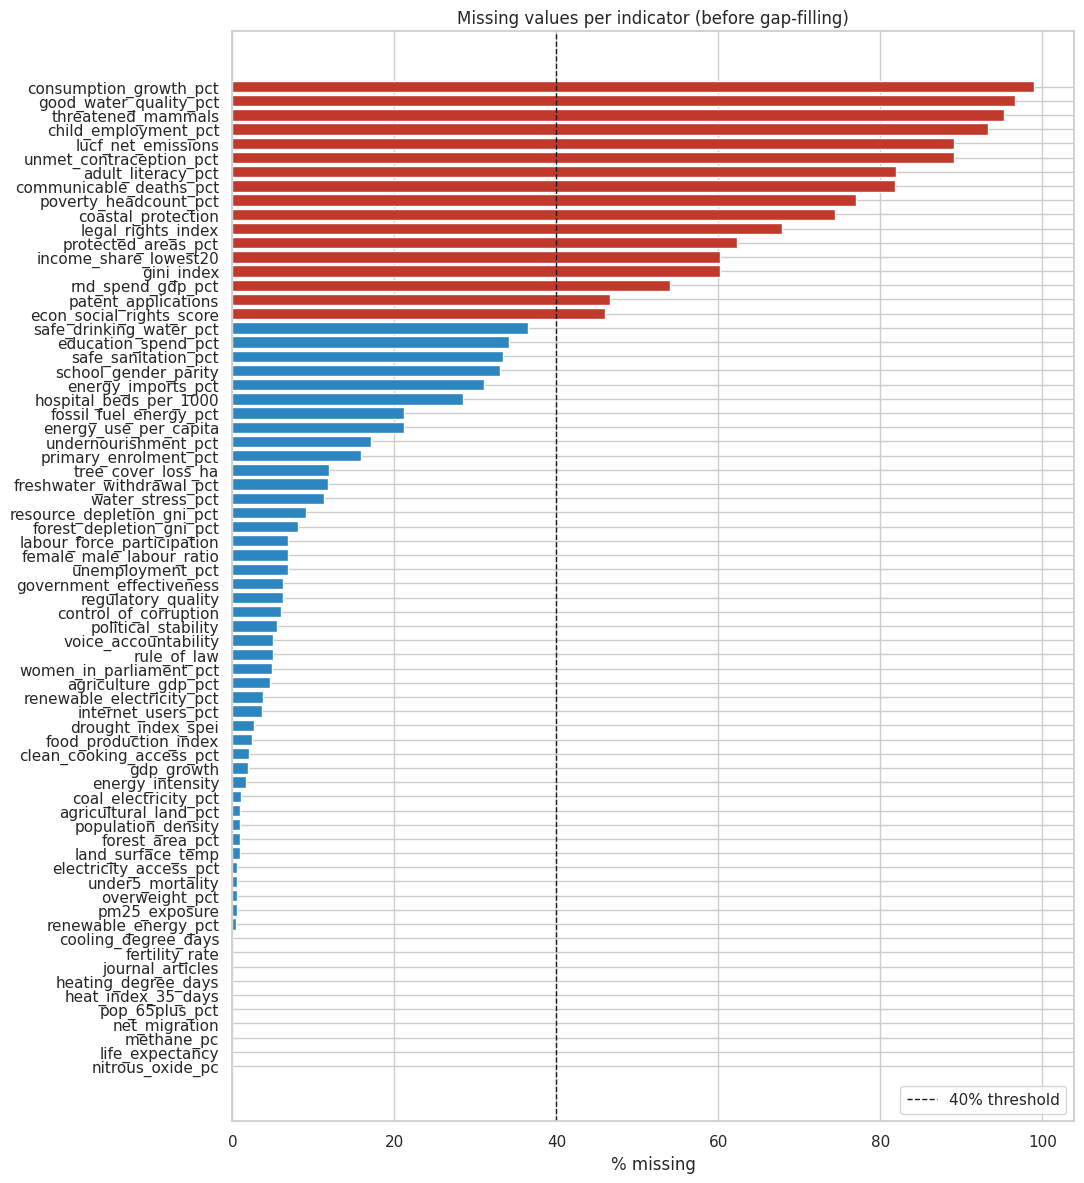

In [ ]:
ID_COLS  = ["country_code", "country", "year"]
CAT_COLS = ["region", "income_group"]
TARGET   = "co2_per_capita"
num_cols_all = [c for c in df.columns if c not in ID_COLS + CAT_COLS + [TARGET]]

print("Duplicate country-year rows:", df.duplicated(["country_code", "year"]).sum())
print("Numeric indicator columns:", len(num_cols_all))
print("Overall missing (numeric features): %.1f%%" % (100 * df[num_cols_all].isna().mean().mean()))
print("\nRows per income group:\n", df["income_group"].value_counts().to_string())
print("\nYears per country: min %d, median %d, max %d"
      % tuple(df.groupby("country_code").size().agg(["min", "median", "max"])))

missing = (df[num_cols_all].isna().mean() * 100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(11, 12))
colors = ["#c0392b" if m > 40 else "#2e86c1" for m in missing.values]
ax.barh(missing.index[::-1], missing.values[::-1], color=colors[::-1])
ax.axvline(40, color="k", ls="--", lw=1, label="40% threshold")
ax.set_xlabel("% missing"); ax.set_title("Missing values per indicator (before gap-filling)")
ax.legend(loc="lower right")
savefig("04_missing_per_column")

**What this shows.** There are no duplicate rows, and almost every country has all 21 years. Missingness varies hugely between indicators:

- About two-thirds of the indicators are almost complete (under ~10% missing).
- A group of survey-based indicators (Gini index, poverty headcount, literacy, child employment and others) are only measured every few years, so most country-years are empty.

Two decisions follow:

1. **Fill short gaps within each country** (Section 5), because many indicators are measured every 2–5 years and change slowly.
2. **Drop indicators that are still more than 40% missing** after that step. Imputing most of a column would mean the model learns from invented values. This rule is part of the preprocessing pipeline, so it is **re-applied inside every cross-validation fold** using only that fold's training countries (Section 8).

### 4.2 Leakage audit

A feature *leaks* if it contains the answer rather than a cause. I checked every feature's correlation with the target and looked at how each is produced:

- **`methane_pc`, `nitrous_oxide_pc`**: greenhouse-gas emissions per person from the **same emissions inventory** as the target. They are co-produced by the same activities (fuel extraction, combustion, agriculture), so they are other outputs of the same accounting rather than drivers. **Dropped.**
- **`lucf_net_emissions`**: net emissions from land use and forestry, also an emissions-accounting output. **Dropped.**
- **`energy_use_per_capita`** and **`fossil_fuel_energy_pct`** are strongly linked to CO₂ for a physical reason: CO₂ is produced by burning fossil energy. They are energy statistics, not emissions estimates, and they are what an analyst would have when benchmarking a country, so they are **kept**. This makes the task easier, which is acknowledged as a limitation (Section 14). Their dominance is examined in the XAI section.

In [ ]:
LEAKY = ["methane_pc", "nitrous_oxide_pc", "lucf_net_emissions"]

corr_with_target = (df[num_cols_all]
                    .corrwith(np.log1p(df[TARGET]), method="spearman")
                    .sort_values(key=np.abs, ascending=False))
leak_view = pd.DataFrame({"spearman_r_with_log_co2": corr_with_target.round(3),
                          "flag": ["LEAKAGE - dropped" if c in LEAKY else "" for c in corr_with_target.index]})
display(leak_view.head(12))
display(leak_view.loc[[c for c in LEAKY if c in leak_view.index]])

,spearman_r_with_log_co2,flag
energy_use_per_capita,0.958,
clean_cooking_access_pct,0.876,
electricity_access_pct,0.862,
safe_drinking_water_pct,0.854,
agriculture_gdp_pct,-0.839,
under5_mortality,-0.813,
safe_sanitation_pct,0.796,
communicable_deaths_pct,-0.777,
life_expectancy,0.773,
undernourishment_pct,-0.771,


,spearman_r_with_log_co2,flag
methane_pc,0.381,LEAKAGE - dropped
nitrous_oxide_pc,0.174,LEAKAGE - dropped
lucf_net_emissions,0.118,LEAKAGE - dropped


## 5. Feature construction and train/test split

### 5.1 Row-level feature construction (before the split)

Only steps that **learn nothing across countries** are done here, so doing them before the split cannot leak information between training and test:

1. **Drop leakage columns** (Section 4.2).
2. **Within-country gap-filling.** Many indicators are reported every few years and change slowly, e.g. hospital beds or protected area. For each country separately, I linearly interpolate across years and extend the nearest observed value by at most **3 years** at either end (`limit=3`). This uses only that country's own values, and every country is entirely in either the training set or the test set, so no information crosses between training and test countries. Gaps longer than 3 years are left missing and handled by the pipeline.

   **Limitation:** interpolation uses **later** years to fill **earlier** ones (e.g. a 2008 value helps fill 2006). That is acceptable here because the task is retrospective estimation for observed years (Section 3), but it would **not** be available in a real forecast. To check that this choice does not drive the results, I also build a **past-only** version (forward-fill only, no future information) and compare cross-validation scores in Section 9.1.
3. **Engineered feature `income_level`**: income group as an **ordered** number (Low = 0 … High = 3). Income groups have a natural order, so an ordinal code lets tree models split "low vs higher income" in one step rather than across four one-hot columns. Region has no order, so it is one-hot encoded later.

Anything that **learns statistics** (dropping by missing %, median imputation, scaling, log-transform choice, PCA) happens later, inside the pipeline, and is fitted on the training part of each fold only.

In [ ]:
INCOME_ORDER = ["Low income", "Lower middle income", "Upper middle income", "High income"]

data = df.drop(columns=[c for c in LEAKY if c in df.columns]).copy()
num_feats = [c for c in num_cols_all if c not in LEAKY]

data = data.sort_values(["country_code", "year"]).reset_index(drop=True)
raw_feats = data[num_feats].copy()          # before gap-filling (kept for the sensitivity check)
before = raw_feats.isna().mean().mean() * 100

# Main version: interpolate within each country (uses neighbouring years on both sides)
data[num_feats] = (data.groupby("country_code")[num_feats]
                       .transform(lambda s: s.interpolate(limit=3, limit_direction="both")))
# Past-only version for the sensitivity check: carry the last observed value forward (no future years)
past_only = raw_feats.groupby(data["country_code"]).ffill(limit=3)

after = data[num_feats].isna().mean().mean() * 100
print(f"Missing values: before gap-filling {before:.1f}% -> interpolation {after:.1f}% "
      f"-> past-only fill {past_only.isna().mean().mean() * 100:.1f}%")

data["income_level"] = data["income_group"].map({g: i for i, g in enumerate(INCOME_ORDER)})

Missing values: before gap-filling 23.9% -> interpolation 16.0% -> past-only fill 19.5%


### 5.2 Train/test split, grouped by country

80% of **countries** go to training and 20% to testing. All years of a country stay together. The test set is locked away until Section 12; EDA, PCA, preprocessing choices, model selection and tuning all use the **training set only**. With only 39 test countries, the test score is itself uncertain, so Sections 9.2 and 12 add repeated cross-validation and bootstrap intervals.

In [ ]:
X_all = data.drop(columns=[TARGET])
y_all = np.log1p(data[TARGET])            # modelling target: log1p(t CO2 per person)
groups_all = data["country_code"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, test_idx = next(gss.split(X_all, y_all, groups=groups_all))

train_df, test_df = data.iloc[train_idx].copy(), data.iloc[test_idx].copy()
X_train, X_test = X_all.iloc[train_idx].copy(), X_all.iloc[test_idx].copy()
y_train, y_test = y_all.iloc[train_idx].copy(), y_all.iloc[test_idx].copy()
groups_train = np.asarray(groups_all.iloc[train_idx], dtype=object)   # plain numpy array of country codes

assert set(train_df.country_code).isdisjoint(test_df.country_code)   # no country in both
print(f"Train: {len(train_df):,} rows, {train_df.country_code.nunique()} countries")
print(f"Test : {len(test_df):,} rows, {test_df.country_code.nunique()} countries")
print("\nTarget (t CO2 per person) in each split:")
display(pd.DataFrame({"train": train_df[TARGET].describe(), "test": test_df[TARGET].describe()}).round(2).T)
print("Test countries:", ", ".join(sorted(test_df.country.unique())))

Train: 3,192 rows, 152 countries
Test : 819 rows, 39 countries

Target (t CO2 per person) in each split:


,count,mean,std,min,25%,50%,75%,max
train,3192.0,4.38,5.89,0.00,0.66,2.19,6.00,47.94
test,819.0,3.98,3.45,0.06,0.54,3.84,6.13,17.43


Test countries: Argentina, Austria, Bahamas, The, Bangladesh, Barbados, Bosnia and Herzegovina, Bulgaria, Cambodia, Chad, Cyprus, Djibouti, Equatorial Guinea, Gabon, Gambia, The, Greece, Grenada, Guinea-Bissau, Hungary, Indonesia, Lebanon, Libya, Madagascar, Mali, Nigeria, North Macedonia, Norway, Oman, Poland, Samoa, Serbia, Sierra Leone, South Sudan, St. Vincent and the Grenadines, Suriname, Sweden, Switzerland, Syrian Arab Republic, Turkmenistan, Uzbekistan


In [ ]:
MISSING_THRESHOLD = 0.40
ALL_NUM_FEATURES = num_feats + ["year"]       # model inputs: the pipeline drops sparse ones INSIDE each fold

# For EDA and PCA (exploration of the training set only) I use the columns that pass the threshold on
# the full training set. The models never use this list: they re-apply the rule fold by fold (Section 8).
train_missing = X_train[num_feats].isna().mean()
DROPPED_SPARSE = sorted(train_missing[train_missing > MISSING_THRESHOLD].index)
NUM_FEATURES = [c for c in num_feats if c not in DROPPED_SPARSE] + ["year"]
print(f"{len(DROPPED_SPARSE)} indicators are >{MISSING_THRESHOLD:.0%} missing in the training data "
      f"(excluded from EDA/PCA; the model pipeline re-checks this in every fold):")
print("  " + ", ".join(DROPPED_SPARSE))
print(f"\nEDA/PCA use {len(NUM_FEATURES)} numeric features (incl. year)")

9 indicators are >40% missing in the training data (excluded from EDA/PCA; the model pipeline re-checks this in every fold):
  child_employment_pct, coastal_protection, consumption_growth_pct, good_water_quality_pct, legal_rights_index, poverty_headcount_pct, protected_areas_pct, threatened_mammals, unmet_contraception_pct

EDA/PCA use 59 numeric features (incl. year)


### 5.3 A fold-safe preprocessing building block

To make sure **no preprocessing decision is learned outside a validation fold**, all *learned* numeric preprocessing is packed into one scikit-learn transformer, `NumericPrep`. When it is placed inside a `Pipeline`, `cross_validate` and `RandomizedSearchCV` refit it on the training part of every fold, so each fold decides for itself:

1. which indicators are too sparse (> 40% missing) and are dropped;
2. which indicators are strongly skewed (skewness > 2) and get a log transform (linear models only);
3. the median used to fill remaining gaps;
4. the mean and standard deviation used for scaling (linear models only).

It is used in the PCA experiment (7.1) and in every model pipeline (Section 8).

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

class NumericPrep(BaseEstimator, TransformerMixin):
    # Learned numeric preprocessing; everything below is decided in fit() from the data it is fitted on.
    def __init__(self, threshold=0.40, log_skewed=True, skew_limit=2.0, scale=True):
        self.threshold = threshold
        self.log_skewed = log_skewed
        self.skew_limit = skew_limit
        self.scale = scale

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.n_features_in_ = X.shape[1]
        miss = X.isna().mean()
        self.keep_ = [c for c in X.columns if miss[c] <= self.threshold]       # 1) drop sparse columns
        self.dropped_ = [c for c in X.columns if miss[c] > self.threshold]
        Xk = X[self.keep_].astype(float)
        self.log_cols_, self.signed_log_cols_ = [], []
        if self.log_skewed:                                                     # 2) choose skewed columns
            sk, mn = Xk.skew(), Xk.min()
            self.log_cols_ = [c for c in self.keep_ if sk[c] > self.skew_limit and mn[c] >= 0]
            self.signed_log_cols_ = [c for c in self.keep_ if sk[c] > self.skew_limit and mn[c] < 0]
        Xk = self._log(Xk)
        self.medians_ = Xk.median()                                             # 3) imputation values
        Xk = Xk.fillna(self.medians_)
        if self.scale:                                                          # 4) scaling values
            sd = Xk.std(ddof=0)
            self.means_, self.stds_ = Xk.mean(), sd.where(sd > 0, 1.0)
        return self

    def _log(self, Xk):
        Xk = Xk.copy()
        if self.log_cols_:
            Xk[self.log_cols_] = np.log1p(Xk[self.log_cols_].clip(lower=0))
        if self.signed_log_cols_:
            v = Xk[self.signed_log_cols_]
            Xk[self.signed_log_cols_] = np.sign(v) * np.log1p(v.abs())
        return Xk

    def transform(self, X):
        Xk = self._log(pd.DataFrame(X)[self.keep_].astype(float)).fillna(self.medians_)
        if self.scale:
            Xk = (Xk - self.means_) / self.stds_
        return Xk

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.keep_, dtype=object)

print("NumericPrep defined")

NumericPrep defined


## 6. Exploratory data analysis (training set only)

EDA uses the training countries only, so that no impressions from the test set influence modelling choices.

### 6.1 Target distribution

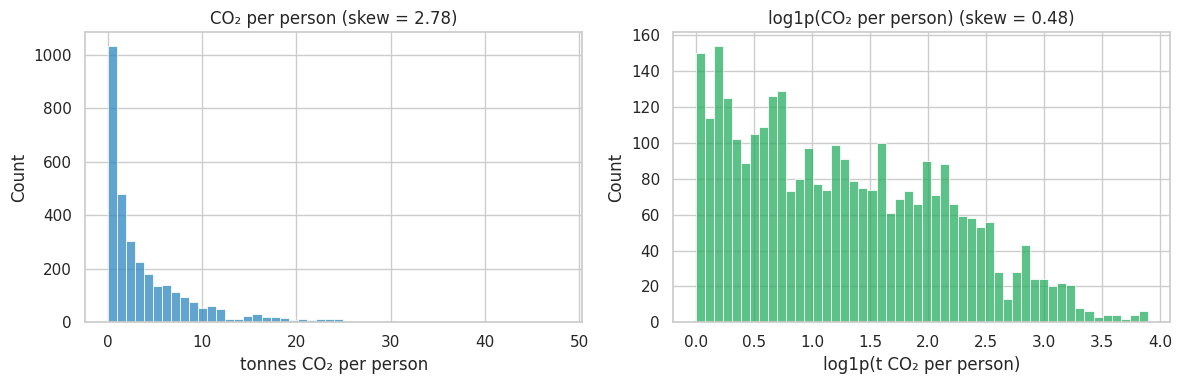

count    3192.00
mean        4.38
std         5.89
min         0.00
25%         0.66
50%         2.19
75%         6.00
max        47.94

Highest average emitters (train): Qatar 39.9t, Kuwait 25.8t, United Arab Emirates 23.3t, Bahrain 22.5t, Luxembourg 19.8t
Lowest average emitters (train):  Malawi 0.07t, Somalia, Fed. Rep. 0.05t, Central African Republic 0.05t, Congo, Dem. Rep. 0.04t, Burundi 0.03t


In [ ]:
co2 = train_df[TARGET]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(co2, bins=50, ax=ax[0], color="#2e86c1")
ax[0].set(title=f"CO₂ per person (skew = {co2.skew():.2f})", xlabel="tonnes CO₂ per person")
sns.histplot(np.log1p(co2), bins=50, ax=ax[1], color="#27ae60")
ax[1].set(title=f"log1p(CO₂ per person) (skew = {np.log1p(co2).skew():.2f})", xlabel="log1p(t CO₂ per person)")
savefig("06_target_distribution")
print(co2.describe().round(2).to_string())
top = train_df.groupby("country")[TARGET].mean().sort_values(ascending=False)
print("\nHighest average emitters (train):", ", ".join(f"{c} {v:.1f}t" for c, v in top.head(5).items()))
print("Lowest average emitters (train): ", ", ".join(f"{c} {v:.2f}t" for c, v in top.tail(5).items()))

**Observation: the target is extremely skewed, which justifies the log scale.** Raw CO₂ per person has a skew of about 2.8:

- **71%** of training country-years emit under 5 t per person;
- about **3%** emit more than 20 t, almost all of them Gulf oil producers (Qatar averages ~40 t);
- the lowest emitters (Burundi, DR Congo, Central African Republic) emit under 0.1 t.

That is a ratio of more than 1,000 to 1 between the highest and lowest. After `log1p` the skew drops to about **0.5** (close to symmetric). This supports the decision in Section 3 to model the log, so the model is not dominated by a few extreme emitters.

### 6.2 Univariate view of key features

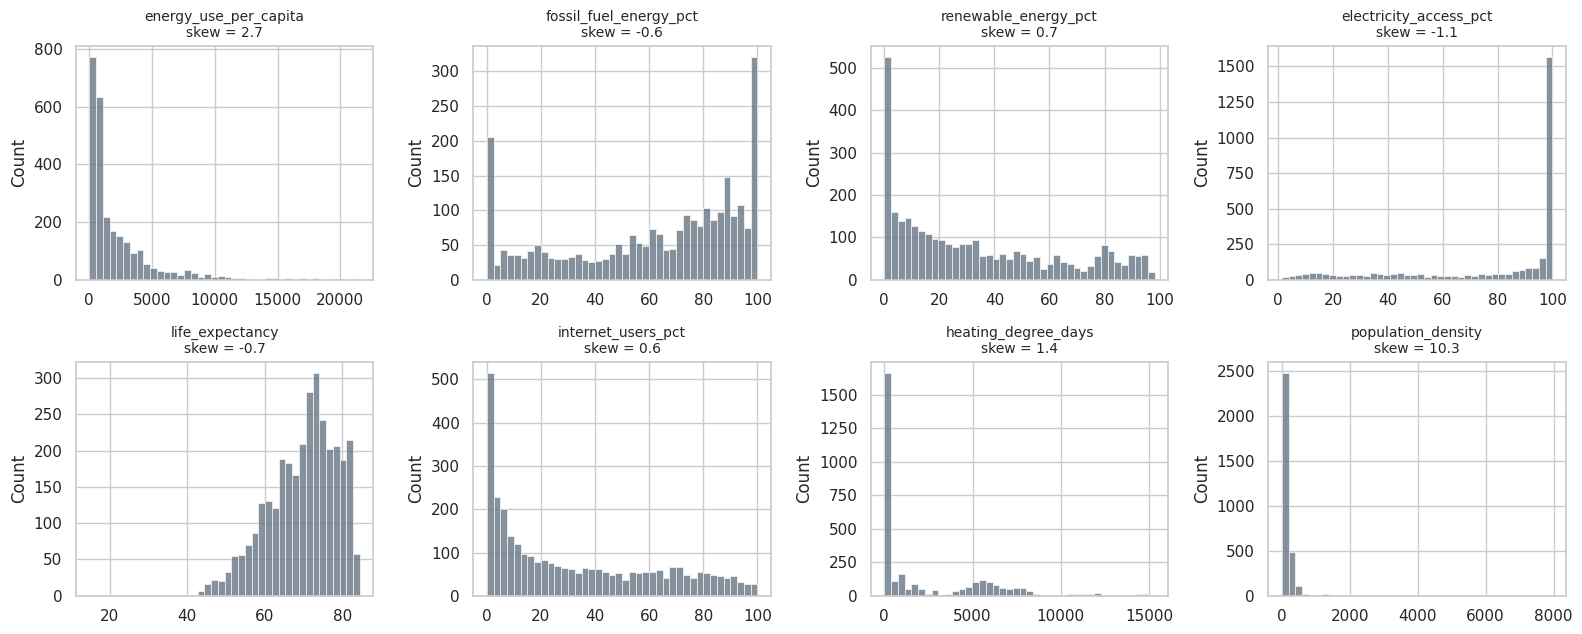

,count,mean,std,min,25%,50%,75%,max
energy_use_per_capita,2655.0,2289.41,3038.96,9.73,478.52,995.28,2870.05,21557.48
fossil_fuel_energy_pct,2655.0,61.19,32.46,0.00,34.64,70.89,88.84,100.00
renewable_energy_pct,3190.0,33.08,29.69,0.00,7.00,24.60,54.60,98.30
electricity_access_pct,3182.0,78.09,30.24,1.30,57.35,97.25,100.00,100.00
life_expectancy,3192.0,69.71,8.82,14.66,64.12,71.21,76.43,84.56
internet_users_pct,3168.0,32.84,29.95,0.00,5.60,23.40,58.10,100.00
heating_degree_days,3192.0,2420.83,3387.55,0.00,0.07,265.59,5072.98,15327.69
population_density,3180.0,189.46,603.53,1.54,32.14,77.95,179.23,7965.88


In [ ]:
KEY = ["energy_use_per_capita", "fossil_fuel_energy_pct", "renewable_energy_pct", "electricity_access_pct",
       "life_expectancy", "internet_users_pct", "heating_degree_days", "population_density"]
KEY = [k for k in KEY if k in NUM_FEATURES]
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, c in zip(axes.ravel(), KEY):
    sns.histplot(train_df[c].dropna(), bins=40, ax=ax, color="#5d6d7e")
    ax.set_title(f"{c}\nskew = {train_df[c].skew():.1f}", fontsize=10); ax.set_xlabel("")
savefig("06_key_feature_histograms")
display(train_df[KEY].describe().T.round(2))

**Observation: several features have long right tails, and some pile up at a boundary.**

- **Long right tails:** energy use per person has a mean of ~2,290 kg oil-equivalent but a median of only ~995, and population density is extremely skewed (skew ≈ 10, driven by city-states such as Singapore and Bahrain). Long tails matter for linear models, so the linear pipeline log-transforms strongly skewed features (Section 8). Trees are unaffected.
- **Boundary pile-ups (ceiling effects):** electricity access has a median of 97% with a spike at 100%, and fossil-fuel share also spikes at 100%. Many countries are at the maximum, so these features mainly separate less-developed countries from the rest.
- **Missing values:** energy use and fossil-fuel share are missing for about 17% of training rows (count 2,655 of 3,192), which is why imputation is needed.

### 6.3 Bivariate: emissions by income group and region

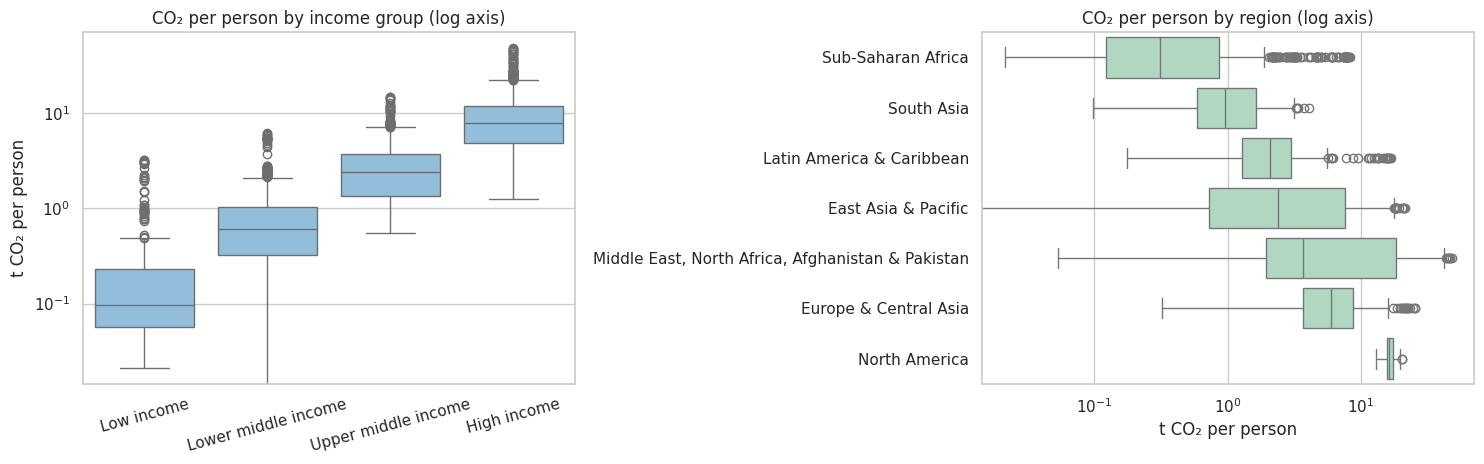

,median t/person
income_group,
Low income,0.10
Lower middle income,0.61
Upper middle income,2.42
High income,7.87


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
sns.boxplot(data=train_df, x="income_group", y=TARGET, order=INCOME_ORDER, ax=ax[0], color="#85c1e9")
ax[0].set_yscale("log"); ax[0].set(title="CO₂ per person by income group (log axis)", xlabel="", ylabel="t CO₂ per person")
ax[0].tick_params(axis="x", rotation=15)
reg_order = train_df.groupby("region")[TARGET].median().sort_values().index
sns.boxplot(data=train_df, y="region", x=TARGET, order=reg_order, ax=ax[1], color="#a9dfbf")
ax[1].set_xscale("log"); ax[1].set(title="CO₂ per person by region (log axis)", ylabel="", xlabel="t CO₂ per person")
savefig("06_target_by_income_region")
display(train_df.groupby("income_group")[TARGET].median().reindex(INCOME_ORDER).round(2).to_frame("median t/person"))

**Observation: income group separates emission levels strongly.** The median high-income country-year emits **7.9 t** per person, compared with **0.10 t** for low-income countries, about **80 times** more. Each step up the income ladder goes with roughly 3–6× higher median emissions, which supports encoding income as an *ordered* feature (`income_level`).

By region, North America (≈16 t) and Europe & Central Asia (≈6 t) have the highest medians and Sub-Saharan Africa the lowest (≈0.3 t). The spread *within* regions is still very wide (e.g. the Middle East includes both Qatar and Yemen), so region alone cannot account for emissions.

*These are associations: income group is a summary of many correlated characteristics, so this plot does not show that income itself causes emissions.*

### 6.4 Bivariate: which features move with emissions?

Spearman (rank) correlation is used because many relationships are monotonic but not linear, and it is robust to the heavy skew.

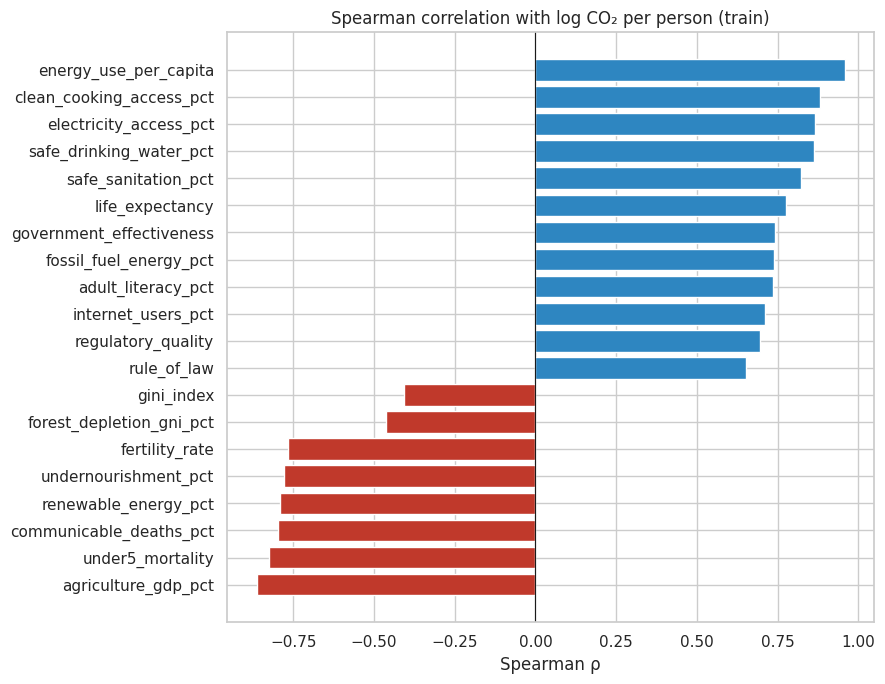

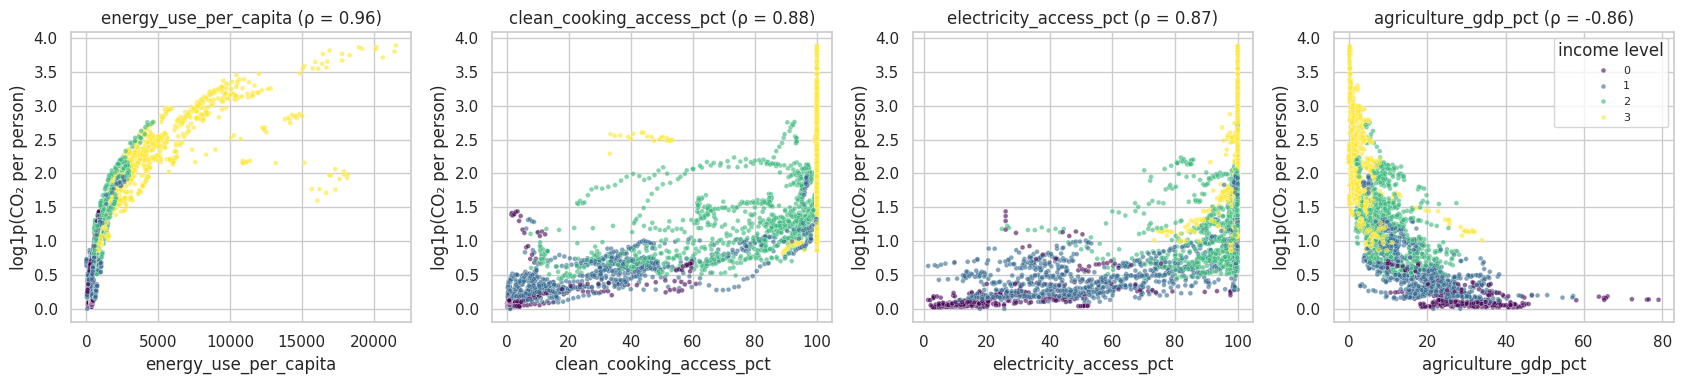

In [ ]:
rho = (train_df[NUM_FEATURES].corrwith(np.log1p(train_df[TARGET]), method="spearman")
       .dropna().sort_values())
show = pd.concat([rho.head(8), rho.tail(12)])
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(show.index, show.values, color=["#c0392b" if v < 0 else "#2e86c1" for v in show.values])
ax.axvline(0, color="k", lw=0.8)
ax.set(title="Spearman correlation with log CO₂ per person (train)", xlabel="Spearman ρ")
savefig("06_spearman_with_target")

top4 = rho.abs().sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, c in zip(axes, top4):
    sns.scatterplot(data=train_df, x=c, y=np.log1p(train_df[TARGET]), hue="income_level",
                    palette="viridis", s=12, alpha=0.6, ax=ax, legend=(c == top4[-1]))
    ax.set(title=f"{c} (ρ = {rho[c]:.2f})", ylabel="log1p(CO₂ per person)")
if axes[-1].get_legend(): axes[-1].legend(title="income level", fontsize=8)
savefig("06_top_feature_scatter")

**Observation: energy and development indicators have the strongest associations, and the relationships are non-linear.**

- **Energy use per person** has by far the strongest rank correlation with emissions (ρ ≈ 0.96). This is expected physically, since fossil CO₂ is produced by burning energy.
- Next come **development-related indicators**: access to clean cooking fuels and electricity, safe drinking water and life expectancy (ρ ≈ 0.8–0.9), and, negatively, agriculture's share of GDP, under-5 mortality and fertility.
- **Renewable energy share** is strongly *negatively* associated (ρ ≈ −0.77). Part of this is compositional: the poorest countries rely on traditional biomass (wood, charcoal), which counts as "renewable", so this correlation mixes clean modern energy with low development.

Many of these indicators are themselves highly correlated (6.6), so these correlations cannot tell us which variable matters *independently*. The scatter plots show curved and step-like rather than straight-line patterns, which suggests non-linear models such as tree ensembles may fit better than a linear model.

### 6.5 Trends over time

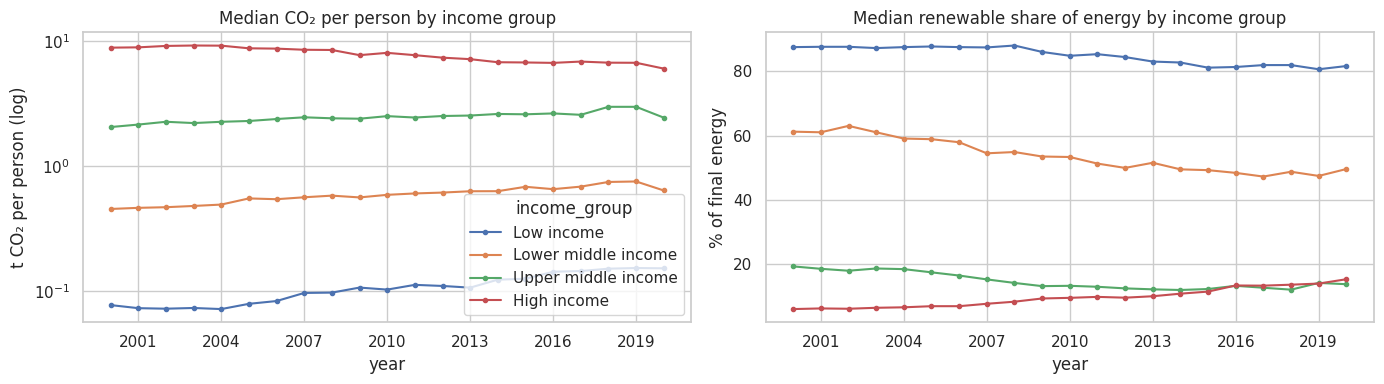

Change in median CO2 per person 2000->2020: Low income: +97%, Lower middle income: +41%, Upper middle income: +19%, High income: -32%


In [ ]:
trend = train_df.groupby(["year", "income_group"])[TARGET].median().unstack()[INCOME_ORDER]
ren = train_df.groupby(["year", "income_group"])["renewable_energy_pct"].median().unstack()[INCOME_ORDER]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
trend.plot(ax=ax[0], marker="o", ms=3); ax[0].set_yscale("log")
ax[0].set(title="Median CO₂ per person by income group", ylabel="t CO₂ per person (log)")
ren.plot(ax=ax[1], marker="o", ms=3, legend=False)
ax[1].set(title="Median renewable share of energy by income group", ylabel="% of final energy")
for a in ax:
    a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
savefig("06_trends_over_time")
chg = (trend.loc[2020] / trend.loc[2000] - 1) * 100
print("Change in median CO2 per person 2000->2020:", ", ".join(f"{g}: {v:+.0f}%" for g, v in chg.items()))

**Observation: the gap between income groups narrowed.** Between 2000 and 2020, the *median* emissions of low-income training countries roughly **doubled (+97%)** and lower-middle-income medians rose by about 40%, while the high-income median **fell by about 32%**. Over the same period the high-income median renewable share rose from about 7% to 15%, while the low-income median fell slightly.

These are medians of the training countries only. They show that the groups' typical values moved closer together; they do not show *why* (fuel switching, economic growth, offshoring of industry and data revisions are all possible). For modelling, the relationship shifts slowly over time, so `year` is kept as a feature.

### 6.6 Multivariate: correlation between predictors

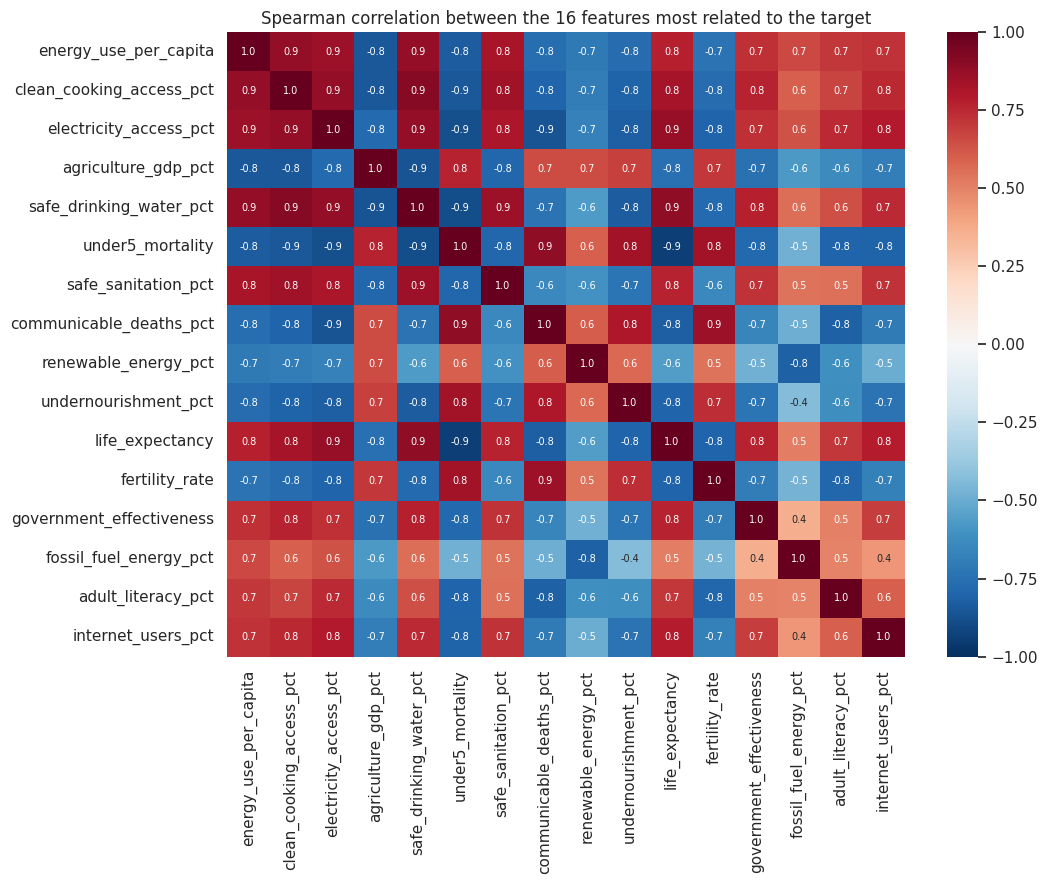

Feature pairs with |ρ| > 0.8: 51


,,|spearman ρ|
gini_index,income_share_lowest20,0.959
life_expectancy,under5_mortality,0.938
freshwater_withdrawal_pct,water_stress_pct,0.924
government_effectiveness,regulatory_quality,0.919
control_of_corruption,rule_of_law,0.917
clean_cooking_access_pct,safe_drinking_water_pct,0.914
government_effectiveness,rule_of_law,0.904
safe_drinking_water_pct,under5_mortality,0.888
control_of_corruption,government_effectiveness,0.886
communicable_deaths_pct,under5_mortality,0.885


In [ ]:
top_feats = rho.abs().sort_values(ascending=False).index[:16]
cm = train_df[top_feats].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(cm, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Spearman correlation between the 16 features most related to the target")
savefig("06_feature_correlation_heatmap")

full = train_df[NUM_FEATURES].corr(method="spearman").abs()
pairs = (full.where(np.triu(np.ones(full.shape, dtype=bool), k=1)).stack()
         .sort_values(ascending=False))
print(f"Feature pairs with |ρ| > 0.8: {(pairs > 0.8).sum()}")
display(pairs.head(10).round(3).to_frame("|spearman ρ|"))

**Observation: strong multicollinearity.** **51** pairs of features have |ρ| > 0.8. Examples:

- the six governance indicators (government effectiveness, rule of law, control of corruption …) are near-duplicates of each other;
- life expectancy and under-5 mortality (ρ = 0.94);
- the Gini index and the income share of the poorest 20% (ρ = 0.96).

**Consequences:**

1. A plain linear model would have unstable coefficients, so Ridge (L2 regularisation) is used rather than ordinary least squares.
2. PCA may be able to compress these features (tested in Section 7).
3. XAI must be interpreted with care: correlated features share or swap credit, which is why grouped SHAP (13.1b) and ALE are added alongside individual SHAP and PDP.

## 7. Principal Component Analysis (PCA)

**Purpose:** to understand the structure of the predictors (how many independent "dimensions" of variation there are) and to decide, with evidence, whether PCA should be part of the model.

**Method:** PCA is variance-based, so features on large scales (e.g. heating degree days, in the thousands) would dominate. I therefore **impute (median) and standardise first**. The imputer, scaler and PCA are all fitted on the **training set only** and then applied unchanged to new data. PCA uses the numeric indicators only; region is left out because PCA on one-hot dummies is hard to interpret.

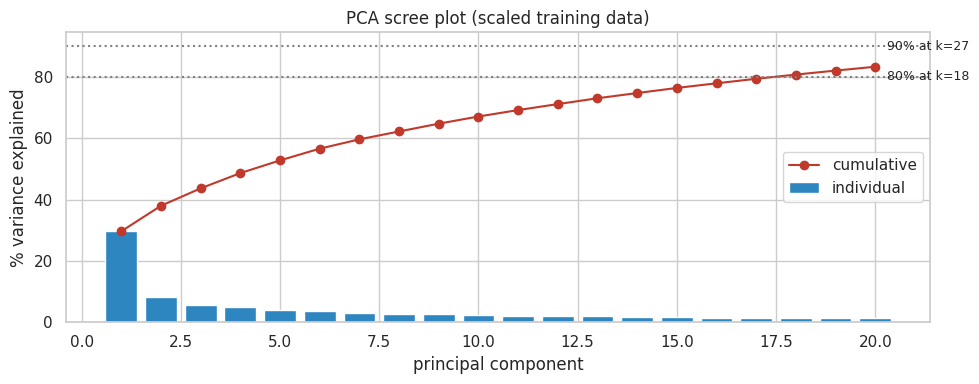

59 features -> PC1 explains 29.6%, PC2 8.3%, PC3 5.7%
Components needed: 80% -> 18, 90% -> 27, 95% -> 36


In [ ]:
PCA_FEATURES = [c for c in NUM_FEATURES if c != "year"] + ["income_level"]
pca_prep = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
Z_train = pca_prep.fit_transform(X_train[PCA_FEATURES])
pca = PCA(random_state=SEED).fit(Z_train)

evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
n80, n90, n95 = (np.argmax(cum >= t) + 1 for t in (0.80, 0.90, 0.95))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(1, 21), evr[:20] * 100, color="#2e86c1", label="individual")
ax.plot(range(1, 21), cum[:20] * 100, "o-", color="#c0392b", label="cumulative")
for t, n in [(80, n80), (90, n90)]:
    ax.axhline(t, ls=":", color="grey"); ax.text(20.3, t, f"{t}% at k={n}", va="center", fontsize=9)
ax.set(xlabel="principal component", ylabel="% variance explained", title="PCA scree plot (scaled training data)")
ax.legend(loc="center right")
savefig("07_pca_scree")
print(f"{len(PCA_FEATURES)} features -> PC1 explains {evr[0]:.1%}, PC2 {evr[1]:.1%}, PC3 {evr[2]:.1%}")
print(f"Components needed: 80% -> {n80}, 90% -> {n90}, 95% -> {n95}")

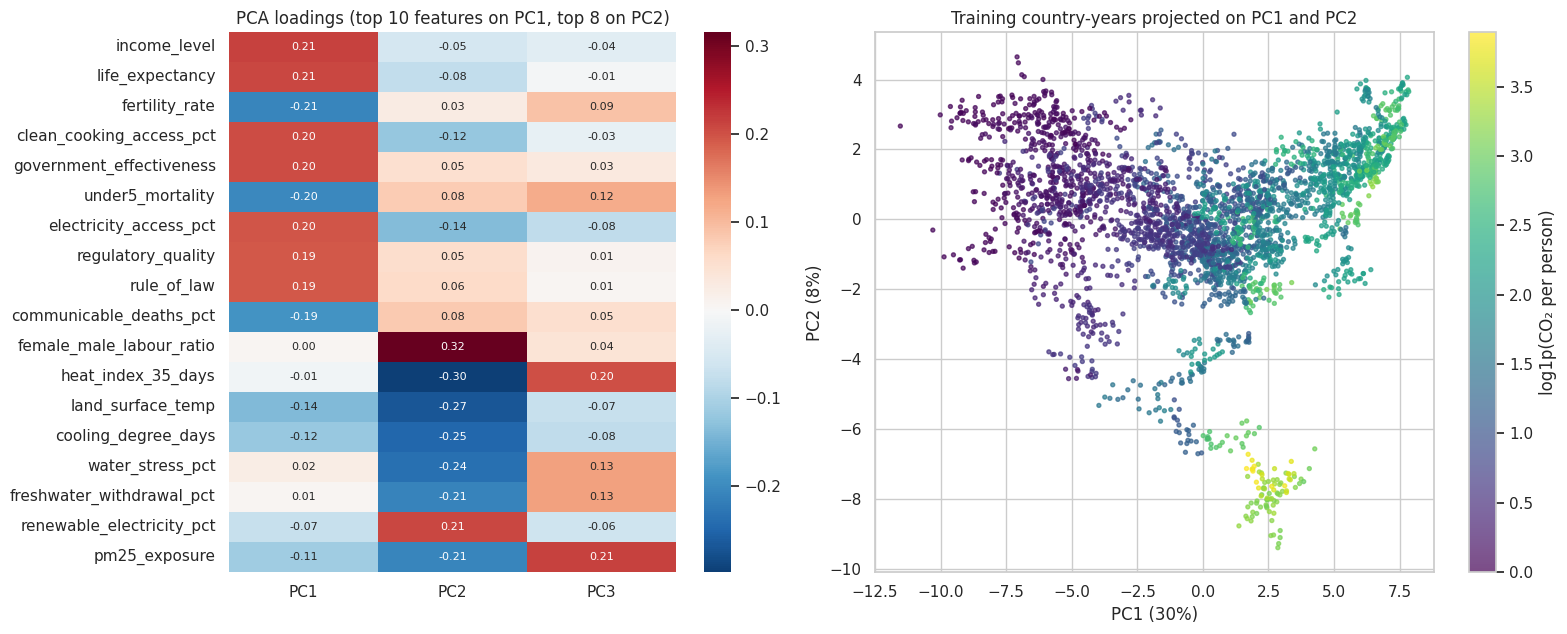

Correlation of PC1 with log CO2: 0.84 | PC2: -0.27
Countries in the separate low-PC2 cluster (PC2 < -6): Bahrain, Egypt, Arab Rep., Kuwait, Qatar, Saudi Arabia, United Arab Emirates


In [ ]:
loadings = pd.DataFrame(pca.components_[:3].T, index=PCA_FEATURES, columns=["PC1", "PC2", "PC3"])
sel = list(dict.fromkeys(list(loadings["PC1"].abs().nlargest(10).index) + list(loadings["PC2"].abs().nlargest(8).index)))
top_load = loadings.loc[sel]
fig, ax = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.25]})
sns.heatmap(top_load, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 8}, ax=ax[0])
ax[0].set_title("PCA loadings (top 10 features on PC1, top 8 on PC2)")

Z2 = pca.transform(Z_train)[:, :2]
sc = ax[1].scatter(Z2[:, 0], Z2[:, 1], c=y_train, cmap="viridis", s=8, alpha=0.7)
plt.colorbar(sc, ax=ax[1], label="log1p(CO₂ per person)")
ax[1].set(xlabel=f"PC1 ({evr[0]:.0%})", ylabel=f"PC2 ({evr[1]:.0%})",
          title="Training country-years projected on PC1 and PC2")
savefig("07_pca_loadings_projection")
print("Correlation of PC1 with log CO2: %.2f | PC2: %.2f"
      % (np.corrcoef(Z2[:, 0], y_train)[0, 1], np.corrcoef(Z2[:, 1], y_train)[0, 1]))
print("Countries in the separate low-PC2 cluster (PC2 < -6):",
      ", ".join(sorted(train_df.loc[Z2[:, 1] < -6, "country"].unique())))

**Interpretation of PCA:**

- **PC1 (≈30% of variance) summarises general development.** It loads positively on income level, life expectancy, clean-cooking access and government effectiveness, and negatively on fertility and under-5 mortality. On its own, PC1 correlates **0.84** with log CO₂: the largest pattern of variation in the predictors is also closely aligned with emissions.
- **PC2 (≈8%) is mainly a hot-climate axis**: heat-index days, land temperature and cooling degree days load strongly negatively, against renewable electricity and female labour participation. The isolated cluster at the bottom of the projection (PC2 < −6) is **Bahrain, Kuwait, Qatar, Saudi Arabia, UAE and Egypt**. Very hot, mostly oil-producing countries, most of them with very high emissions, form a distinct group.
- **Variance is spread out:** 18 components are needed for 80% of the variance and 27 for 90%. Despite the many correlated pairs, the 59 features do not collapse into just a few dimensions.

*Components are statistical summaries of correlated indicators; labels such as "development axis" are my interpretation of the loadings, not measured quantities.*

### 7.1 Should PCA be part of the model? An experiment

I compare 5-fold **grouped** cross-validation (training set only) of a linear model (Ridge) and a tree model (LightGBM), with and without PCA, keeping *k* components. All preprocessing and the PCA itself sit inside the pipeline, so they are refitted in every fold (`NumericPrep` drops sparse columns, imputes and scales per fold).

In [ ]:
gkf = GroupKFold(n_splits=5)
PCA_INPUTS = [c for c in num_feats] + ["income_level"]        # all indicators; sparse ones dropped per fold
pca_rows = []
K_LIST = sorted({5, 10, 20, int(n90), 40})
for k in K_LIST + [None]:
    for name, est in [("Ridge", Ridge(alpha=1.0)),
                      ("LightGBM", LGBMRegressor(n_estimators=300, learning_rate=0.05, random_state=SEED, verbose=-1))]:
        steps = ([("prep", NumericPrep(log_skewed=False, scale=True))]
                 + ([("pca", PCA(n_components=k, random_state=SEED))] if k else []) + [("model", est)])
        cv = cross_validate(Pipeline(steps), X_train[PCA_INPUTS], y_train, groups=groups_train,
                            cv=gkf, scoring="neg_root_mean_squared_error")
        pca_rows.append({"setting": f"PCA k={k}" if k else "No PCA", "model": name,
                         "cv_rmse_log": -cv["test_score"].mean()})
pca_exp = pd.DataFrame(pca_rows).pivot(index="setting", columns="model", values="cv_rmse_log")
pca_exp = pca_exp.loc[[f"PCA k={k}" for k in K_LIST] + ["No PCA"]].round(4)
display(pca_exp)

model,LightGBM,Ridge
setting,,
PCA k=5,0.3872,0.3644
PCA k=10,0.3296,0.2967
PCA k=20,0.3169,0.2766
PCA k=27,0.3256,0.2605
PCA k=40,0.3371,0.2790
No PCA,0.2265,0.2664


**Decision: PCA is *not* used in the final models.** The evidence, with all preprocessing and PCA refitted in each fold:

- **For LightGBM, PCA is worse at every *k*.** The best result with PCA is 0.317 (k = 20) vs **0.227 without**. Keeping more components does not close the gap (0.326 at k = 27, which explains 90% of variance; 0.337 at k = 40).
- **For Ridge, PCA gives only a small gain** (0.261 at k = 27 vs 0.266 without), because it removes the collinearity identified in 6.6. Ridge's own L2 penalty already handles most of this.

**Why keeping many components is not worthwhile here:**

1. **No shortage of data to fix:** with 3,192 rows and ~60 features there is no curse-of-dimensionality problem for PCA to solve.
2. **It removes the structure trees use:** even with 27 components, every component mixes all features. Tree models work by splitting on *individual* features at sharp thresholds (e.g. electricity access ≈ 100%), and PCA blurs those thresholds.
3. **Variance is not relevance:** PCA keeps directions of high variance in the *inputs*, which are not necessarily the directions that matter for *emissions*.
4. **It costs interpretability:** "PC1 raises emissions" is far less useful than "higher energy use per person goes with higher predicted emissions".

So PCA's role in this project is **diagnostic**. It showed a dominant development-related axis aligned with emissions, exposed a distinct cluster of hot oil-producing states, and quantified the redundancy between features.

## 8. Preprocessing pipeline

Everything that learns from data sits inside a scikit-learn `Pipeline` / `ColumnTransformer`, built from `NumericPrep` (5.3) and a one-hot encoder. It is refitted on the training part of **every** cross-validation fold and on the full training set for the final model, so **no decision, not even which columns to drop or log-transform, uses validation or test countries**.

Two versions are used, because linear and tree models need different things:

| Step | Linear pipeline (Ridge) | Tree pipeline (Random Forest, LightGBM) | Why |
|---|---|---|---|
| Sparse indicators (> 40% missing) | dropped (decided per fold) | dropped (decided per fold) | Imputing mostly-empty columns would mean learning from invented values |
| Skewed features (skew > 2) | `log1p`, or signed log if negatives (decided per fold) | not needed | Linear models are hurt by long tails; trees split on rank order, so a monotonic transform changes nothing |
| Missing values | median imputation | median imputation | Median is robust to the skewed distributions seen in EDA. It ignores relationships between features and shrinks variation in imputed columns; the effect is limited because only ~16% of values are imputed after gap-filling (see the Section 14 limitations) |
| Scaling | `StandardScaler` | not needed | Ridge's penalty is scale-sensitive; trees are scale-invariant. Leaving tree inputs in original units makes the XAI plots readable in real units |
| Region | one-hot | one-hot | Nominal category, no order. `handle_unknown="ignore"` protects against unseen values |
| Income | `income_level` ordinal (0–3) | `income_level` ordinal (0–3) | Ordered category (Section 5.1) |

The cell below also shows that the learned decisions really are made per fold: they can differ slightly between folds, which would be impossible if they had been fixed in advance on the whole training set.

In [ ]:
def clean_name(feature, category):
    # e.g. "Middle East, North Africa ..." -> "region_Middle_East_North_Africa_..." (LightGBM rejects , & " in names)
    return f"{feature}_" + re.sub(r"[^A-Za-z0-9]+", "_", str(category)).strip("_")

cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False,
                                              feature_name_combiner=clean_name))])

NUM_INPUTS = ALL_NUM_FEATURES + ["income_level"]

def make_preprocessor(kind):
    if kind == "linear":
        num = NumericPrep(threshold=MISSING_THRESHOLD, log_skewed=True, scale=True)
    else:   # "tree": drop sparse + impute only, original units
        num = NumericPrep(threshold=MISSING_THRESHOLD, log_skewed=False, scale=False)
    return ColumnTransformer([("num", num, NUM_INPUTS), ("cat", cat_pipe, ["region"])], remainder="drop",
                             verbose_feature_names_out=False).set_output(transform="pandas")

MODEL_INPUTS = NUM_INPUTS + ["region"]
X_train_in, X_test_in = X_train[MODEL_INPUTS], X_test[MODEL_INPUTS]

demo = make_preprocessor("linear").fit(X_train_in)
Xt_demo = demo.transform(X_train_in)
num_step = demo.named_transformers_["num"]
print(f"Raw model inputs: {X_train_in.shape[1]} columns -> linear pipeline output: {Xt_demo.shape[1]} columns")
print("Missing after preprocessing:", int(Xt_demo.isna().sum().sum()))
print(f"Fitted on all training countries: dropped {len(num_step.dropped_)} sparse, "
      f"log-transformed {len(num_step.log_cols_)}, signed-log {len(num_step.signed_log_cols_)}")

# The same decisions, re-learned inside each of the 5 grouped CV folds
fold_rows = []
for k, (tr, va) in enumerate(gkf.split(X_train_in, y_train, groups_train), 1):
    f = make_preprocessor("linear").fit(X_train_in.iloc[tr]).named_transformers_["num"]
    fold_rows.append({"fold": k, "n_dropped": len(f.dropped_), "n_logged": len(f.log_cols_) + len(f.signed_log_cols_),
                      "dropped differs from full-train": sorted(set(f.dropped_) ^ set(num_step.dropped_)),
                      "logged differs from full-train": sorted(set(f.log_cols_ + f.signed_log_cols_)
                                                               ^ set(num_step.log_cols_ + num_step.signed_log_cols_))})
display(pd.DataFrame(fold_rows).set_index("fold"))
demo

Raw model inputs: 70 columns -> linear pipeline output: 67 columns
Missing after preprocessing: 0
Fitted on all training countries: dropped 9 sparse, log-transformed 14, signed-log 0


,n_dropped,n_logged,dropped differs from full-train,logged differs from full-train
fold,,,,
1,10,12,[adult_literacy_pct],"[coal_electricity_pct, energy_intensity, net_m..."
2,9,14,[],[]
3,9,13,[],[under5_mortality]
4,9,12,[],"[coal_electricity_pct, food_production_index, ..."
5,10,15,[safe_drinking_water_pct],[rnd_spend_gdp_pct]


ColumnTransformer(transformers=[('num', NumericPrep(),
                                 ['adult_literacy_pct', 'agricultural_land_pct',
                                  'agriculture_gdp_pct', 'child_employment_pct',
                                  'clean_cooking_access_pct',
                                  'coal_electricity_pct', 'coastal_protection',
                                  'communicable_deaths_pct',
                                  'consumption_growth_pct',
                                  'control_of_corruption',
                                  'cooling_degree_days', 'drought_index_spei',
                                  'econ_social_righ...
                                  'freshwater_withdrawal_pct', 'gdp_growth',
                                  'gini_index', 'good_water_quality_pct',
                                  'government_effectiveness',
                                  'heat_index_35_days', ...]),
                                ('cat',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(feature_name_combiner=<function clean_name at 0x7d908113b380>,
                                                                handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['region'])],
                  verbose_feature_names_out=False)

**What this shows.** The pipeline outputs a complete, numeric table with no missing values. The fold table above is evidence that the learned decisions really are made **inside each fold**:

- the set of dropped sparse columns differs in 2 of the 5 folds (e.g. `adult_literacy_pct` crosses the 40% threshold in one fold but not in others);
- the set of log-transformed columns differs slightly in 4 of the 5 folds.

If these choices had been fixed once on the full training set, every fold would show the same list, and each validation fold would have influenced its own preprocessing. Because the whole thing is one pipeline object, exactly the same steps are refitted on each training fold, on the full training set for the final model, and then applied unchanged to validation folds and the test set.

**Effect of the imputation choices.** Median imputation pulls missing values towards the centre of the distribution. It weakens relationships slightly for the affected columns and ignores links between features (e.g. a poor country with missing energy data gets the *median* energy use). This mostly affects indicators with 20–40% missing values; the most important features (energy use, cooking and electricity access) are missing in under ~17% of rows after gap-filling. Dropping sparse indicators loses some information (e.g. Gini index, poverty headcount), but these are survey-based and missing for most country-years, so they could not be relied on for most countries.

## 9. Baseline and model comparison (grouped cross-validation)

Models of **different types** are compared against a naive baseline:

| Model | Type | Why it is a candidate |
|---|---|---|
| **Baseline**: predict the training median | none | Any useful model must clearly beat this |
| **Ridge regression** | linear, regularised | Interpretable by design (coefficients); L2 penalty handles the strongly correlated features seen in 6.6 |
| **Random Forest** | bagged trees | Captures non-linear effects and interactions; robust to outliers; little tuning needed |
| **LightGBM** | gradient-boosted trees | Usually the strongest model on tabular data; fast; many tunable hyperparameters |

**Validation:** 5-fold `GroupKFold` on the training countries, with the whole pipeline inside each fold. I record training scores as well as validation scores to check for overfitting.

,train_rmse,cv_rmse,cv_rmse_sd,cv_mae,train_r2,cv_r2,fit_time_s,overfit_gap
model,,,,,,,,
Baseline (median),0.8870,0.9043,0.0885,0.7655,-0.0184,-0.1483,0.0522,0.0173
Ridge,0.1850,0.2576,0.0481,0.1979,0.9557,0.9061,0.1202,0.0727
Random Forest,0.0181,0.2483,0.0500,0.1656,0.9996,0.9157,39.4851,0.2301
LightGBM,0.0151,0.2287,0.0435,0.1491,0.9997,0.9283,2.0859,0.2136


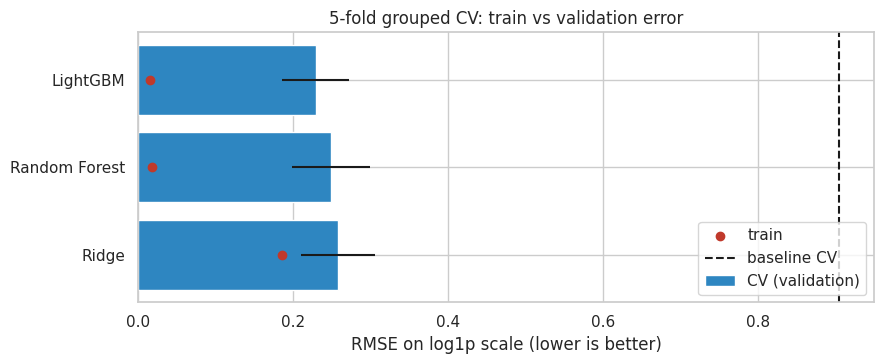

In [ ]:
SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

candidates = {
    "Baseline (median)": Pipeline([("prep", make_preprocessor("tree")), ("model", DummyRegressor(strategy="median"))]),
    "Ridge":             Pipeline([("prep", make_preprocessor("linear")), ("model", Ridge(alpha=1.0))]),
    "Random Forest":     Pipeline([("prep", make_preprocessor("tree")),
                                   ("model", RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1))]),
    "LightGBM":          Pipeline([("prep", make_preprocessor("tree")),
                                   ("model", LGBMRegressor(n_estimators=300, learning_rate=0.05,
                                                           random_state=SEED, verbose=-1))]),
}

rows = []
for name, pipe in candidates.items():
    cv = cross_validate(pipe, X_train_in, y_train, groups=groups_train, cv=gkf,
                        scoring=SCORING, return_train_score=True)
    rows.append({"model": name,
                 "train_rmse": -cv["train_rmse"].mean(), "cv_rmse": -cv["test_rmse"].mean(),
                 "cv_rmse_sd": cv["test_rmse"].std(), "cv_mae": -cv["test_mae"].mean(),
                 "train_r2": cv["train_r2"].mean(), "cv_r2": cv["test_r2"].mean(),
                 "fit_time_s": cv["fit_time"].mean()})
cv_results = pd.DataFrame(rows).set_index("model")
cv_results["overfit_gap"] = cv_results["cv_rmse"] - cv_results["train_rmse"]
display(cv_results.round(4))

fig, ax = plt.subplots(figsize=(9, 3.8))
plot_df = cv_results.drop(index="Baseline (median)")
ax.barh(plot_df.index, plot_df["cv_rmse"], xerr=plot_df["cv_rmse_sd"], color="#2e86c1", label="CV (validation)")
ax.scatter(plot_df["train_rmse"], plot_df.index, color="#c0392b", zorder=3, label="train")
ax.axvline(cv_results.loc["Baseline (median)", "cv_rmse"], color="k", ls="--", label="baseline CV")
ax.set(xlabel="RMSE on log1p scale (lower is better)", title="5-fold grouped CV: train vs validation error")
ax.legend(loc="lower right")
savefig("09_model_comparison")

**Interpretation:**

- **All three models are far better than the baseline.** The baseline's CV RMSE is 0.90 (R² < 0), while all three models reach R² ≈ 0.91–0.93 on validation countries they were not trained on.
- **On these 5 folds, LightGBM scores best** (CV RMSE **0.229**, R² 0.93), followed by Random Forest (0.249) and Ridge (0.258). This is consistent with the non-linear patterns seen in the EDA.
- **Over-fitting check:** both tree models fit the training countries almost perfectly (train RMSE ≈ 0.02), a gap of ~0.21 to CV, while Ridge's gap is only 0.07. A gap like this is common for boosted trees on small data and indicates they fit country-specific detail. Tuning (Section 10) targets this with stronger regularisation.
- **Variability:** the fold-to-fold standard deviation (~0.04–0.05) is about as large as the differences between the three models. Rankings from a single 5-fold split are therefore tentative; Section 10.1 re-checks them on 25 different splits.

**Decision:** LightGBM has the best validation score on this split and trains in under a second (about 13× faster than Random Forest), so it is the model I tune.

### 9.1 Sensitivity check: does the gap-filling method matter?

Section 5.1 filled gaps by interpolating within each country, which uses later years to fill earlier ones. Here the two best model types are re-run with a **past-only** fill (carry the last observed value forward for up to 3 years, never using future years). Everything else is identical.

In [ ]:
X_train_past = X_train_in.copy()
X_train_past[num_feats] = past_only.loc[X_train_in.index, num_feats].values

sens_rows = []
for name in ["Ridge", "LightGBM"]:
    for label, Xv in [("interpolation (main)", X_train_in), ("past-only fill", X_train_past)]:
        cv = cross_validate(candidates[name], Xv, y_train, groups=groups_train, cv=gkf,
                            scoring="neg_root_mean_squared_error")
        sens_rows.append({"model": name, "gap-filling": label, "cv_rmse_log": -cv["test_score"].mean()})
sens = pd.DataFrame(sens_rows).pivot(index="model", columns="gap-filling", values="cv_rmse_log")
sens["difference"] = sens["past-only fill"] - sens["interpolation (main)"]
display(sens.round(4))

gap-filling,interpolation (main),past-only fill,difference
model,,,
LightGBM,0.2287,0.2308,0.0021
Ridge,0.2576,0.2555,-0.0022


**Result: the gap-filling method makes almost no difference.** Switching from two-sided interpolation to a past-only fill changes CV RMSE by only **+0.002 for LightGBM and −0.002 for Ridge**, far smaller than the fold-to-fold variation (~0.04). The past-only fill leaves more values missing (19.5% vs 16.0%), and the pipeline imputes those instead.

So the use of later years in gap-filling is **not driving the results**. The main version is kept because it matches the retrospective purpose of the model (Section 3). For a genuine forecasting application, the past-only version would be the correct choice, and this check suggests it would perform about as well.

## 10. Hyperparameter tuning

I tune the best model family from Section 9, **LightGBM**. I use **randomised search** rather than grid search: with 7 hyperparameters a full grid would need thousands of fits, while random sampling covers the important dimensions far more efficiently (Bergstra & Bengio, 2012). The search uses the same 5-fold **grouped** CV on the training countries, with the whole preprocessing pipeline refitted in every fold; the test set is never used.

**Search space and reasoning:**

- `num_leaves` and `min_child_samples` control tree complexity. With only ~150 training countries, small leaves risk memorising individual countries, so larger minimum leaf sizes are included.
- `learning_rate` and `n_estimators` trade off together: a lower learning rate with more trees usually generalises better.
- `subsample` and `colsample_bytree` add randomness, which reduces variance, especially useful with many correlated features.
- `reg_lambda` is L2 regularisation on leaf values.

In [ ]:
lgbm_pipe = Pipeline([("prep", make_preprocessor("tree")),
                      ("model", LGBMRegressor(random_state=SEED, verbose=-1, subsample_freq=1, n_jobs=1))])
param_dist = {
    "model__num_leaves":        randint(4, 48),
    "model__min_child_samples": randint(10, 120),
    "model__learning_rate":     loguniform(0.01, 0.2),
    "model__n_estimators":      randint(200, 900),
    "model__subsample":         uniform(0.6, 0.4),
    "model__colsample_bytree":  uniform(0.4, 0.6),
    "model__reg_lambda":        loguniform(1e-3, 10),
}
search = RandomizedSearchCV(lgbm_pipe, param_dist, n_iter=30, cv=gkf, scoring="neg_root_mean_squared_error",
                            random_state=SEED, n_jobs=-1, return_train_score=True)
t0 = time.perf_counter()
search.fit(X_train_in, y_train, groups=groups_train)
tune_time = time.perf_counter() - t0

best_i = search.best_index_
tuned_cv = -search.best_score_
default_cv = cv_results.loc["LightGBM", "cv_rmse"]
print(f"Search: 30 candidates x 5 folds in {tune_time:.0f}s")
print(f"Default LightGBM CV RMSE: {default_cv:.4f} -> tuned: {tuned_cv:.4f} "
      f"({(default_cv - tuned_cv) / default_cv:+.1%} improvement on these 5 folds)")
print(f"Tuned train RMSE {-search.cv_results_['mean_train_score'][best_i]:.4f} vs CV {tuned_cv:.4f}")
best_params = {k.replace("model__", ""): (round(v, 4) if isinstance(v, float) else v)
               for k, v in search.best_params_.items()}
best_params

Search: 30 candidates x 5 folds in 282s
Default LightGBM CV RMSE: 0.2287 -> tuned: 0.2092 (+8.5% improvement on these 5 folds)
Tuned train RMSE 0.0355 vs CV 0.2092


{'colsample_bytree': np.float64(0.5192),
 'learning_rate': np.float64(0.0102),
 'min_child_samples': 20,
 'n_estimators': 698,
 'num_leaves': 20,
 'reg_lambda': np.float64(0.7004),
 'subsample': np.float64(0.9161)}

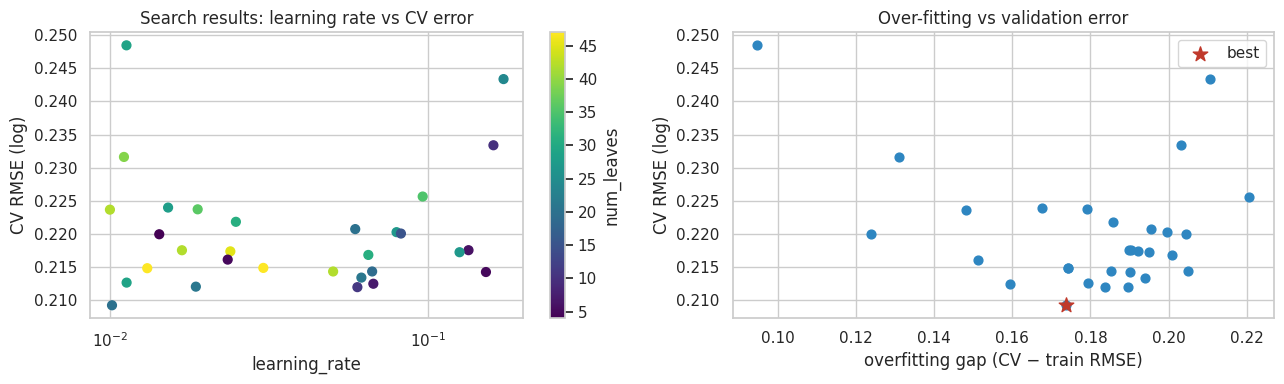

In [ ]:
res = pd.DataFrame(search.cv_results_)
res["cv_rmse"] = -res["mean_test_score"]
res["gap"] = res["cv_rmse"] - (-res["mean_train_score"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
s = ax[0].scatter(res["param_model__learning_rate"].astype(float), res["cv_rmse"],
                  c=res["param_model__num_leaves"].astype(float), cmap="viridis", s=40)
ax[0].set_xscale("log"); plt.colorbar(s, ax=ax[0], label="num_leaves")
ax[0].set(xlabel="learning_rate", ylabel="CV RMSE (log)", title="Search results: learning rate vs CV error")
ax[1].scatter(res["gap"], res["cv_rmse"], color="#2e86c1", s=40)
ax[1].scatter(res.loc[best_i, "gap"], res.loc[best_i, "cv_rmse"], color="#c0392b", s=120, marker="*", label="best")
ax[1].set(xlabel="overfitting gap (CV − train RMSE)", ylabel="CV RMSE (log)", title="Over-fitting vs validation error")
ax[1].legend()
savefig("10_tuning_results")

**Interpretation:**

- **On the search's own 5 folds, tuning lowered CV RMSE by about 8.5%** (0.229 → **0.209**). The best configuration is a cautious one: a **low learning rate (0.01) with ~700 trees**, **~50% of features per tree** (`colsample_bytree` = 0.52) and moderate leaf sizes. Column subsampling forces the model to use more than one of the many correlated features, which suits this dataset.
- **Over-fitting:** the tuned model's training error rose from 0.015 to 0.036, meaning it fits the training countries less tightly. But the train–CV gap is still large (~0.17), so countries the model has seen are predicted much better than new ones.
- **What the search shows:**
  - The right-hand plot shows that configurations with the *largest* train–CV gaps do not achieve better validation scores, so extra complexity does not help.
  - Good scores occur across a range of learning rates, so the result is not very sensitive to any single hyperparameter.
- **Caution, the winner's curse:** this 8.5% was measured on the same folds used to *choose* the configuration, and the best of 30 candidates is optimistic by construction. Section 10.1 therefore re-tests the gain on new splits.

### 10.1 Does tuning *reliably* help? Repeated grouped cross-validation

The tuning gain above was measured on one particular 5-fold split of the countries, the same split the search optimised on. That makes it optimistic (the *winner's curse*). To check whether the gain is real, I re-evaluate the models on **5 new random country splits × 5 folds = 25 validation sets** that the search never saw. All models see exactly the same splits, so the comparison is **paired**.

In [ ]:
def repeated_group_splits(groups, n_splits=5, n_repeats=5, seed=SEED + 100):
    uniq = np.unique(groups)
    splits = []
    for r in range(n_repeats):
        perm = np.random.default_rng(seed + r).permutation(uniq)
        fold_of = {c: i % n_splits for i, c in enumerate(perm)}
        f = np.array([fold_of[g] for g in groups])
        splits += [(np.where(f != k)[0], np.where(f == k)[0]) for k in range(n_splits)]
    return splits

RSPLITS = repeated_group_splits(groups_train)
tuned_pipe = sklearn.base.clone(search.best_estimator_)
rep_models = {"Ridge": candidates["Ridge"], "LightGBM (default)": candidates["LightGBM"],
              "LightGBM (tuned)": tuned_pipe}
rep_scores = {}
for name, pipe in rep_models.items():
    cv = cross_validate(pipe, X_train_in, y_train, cv=RSPLITS, scoring="neg_root_mean_squared_error", n_jobs=-1)
    rep_scores[name] = -cv["test_score"]
rep_df = pd.DataFrame(rep_scores)
display(rep_df.agg(["mean", "std", "min", "max"]).T.round(4))
d = rep_df["LightGBM (tuned)"] - rep_df["LightGBM (default)"]
print(f"Tuned minus default, paired over 25 validation sets: mean {d.mean():+.4f}, "
      f"tuned better in {(d < 0).sum()}/25")

,mean,std,min,max
Ridge,0.2697,0.0281,0.1991,0.3119
LightGBM (default),0.2486,0.0574,0.1268,0.4053
LightGBM (tuned),0.2206,0.0421,0.1411,0.3297


Tuned minus default, paired over 25 validation sets: mean -0.0279, tuned better in 19/25


**Result: on new splits, tuning still helps on average, but not every time.**

- Across 25 validation sets the search never used, the tuned LightGBM has a mean RMSE of **0.221**, against **0.249** for the default LightGBM and **0.270** for Ridge.
- In the **paired** comparison the tuned model is better in **19 of 25** splits (mean improvement 0.028). That is good evidence that the gain is not just the winner's curse.
- But in 6 of 25 splits the default model was better. Validation RMSE also ranges widely depending on which countries are held out: from 0.13 to 0.41 for the default model and 0.14 to 0.33 for the tuned one.

**Implication:** the *same* model can look very good or quite poor depending on which ~30 countries are held out. A single test set of 39 countries (Section 12) is therefore one draw from this wide distribution, and it should be read alongside this evidence, not instead of it. The tuned model also has a smaller spread (sd 0.042 vs 0.057), i.e. it is more consistent across country samples.

## 11. AutoML with FLAML

**Why FLAML?** FLAML (Microsoft) automates model selection and hyperparameter search like H2O AutoML, but it is a pure-Python, scikit-learn-compatible library that needs no Java server, so it runs reliably in Colab. Its cost-frugal search tries cheap configurations first and spends time only on promising ones.

**Configuration (set up for this problem rather than left on defaults):**

- `task="regression"`, `metric="rmse"` on the log target, the same as my manual models;
- `eval_method="cv"` with `split_type="group"` and `groups=` country, so AutoML also never validates on a country it trained on. With the default random split, AutoML would leak across years of the same country and report over-optimistic scores;
- `estimator_list`: LightGBM, XGBoost, Random Forest and Extra Trees, all tree ensembles suited to tabular data;
- `time_budget=120` seconds, enough for a meaningful search while keeping the notebook quick.

**Keeping AutoML's validation clean.** FLAML's internal cross-validation cannot run my scikit-learn pipeline inside each fold. If I imputed and encoded the data *before* giving it to FLAML, those steps would have been learned from all training countries, including each fold's validation countries. So FLAML gets the **raw features with no learned preprocessing**:

- missing values are left as they are, because all four tree libraries handle them natively;
- region is passed as a categorical column with its fixed list of 7 World Bank regions, which is known in advance, not learned from the data.

**Like-for-like comparison.** FLAML's leaderboard score comes from FLAML's own CV and preprocessing. So I then take FLAML's best configuration and **re-score it with exactly the same pipeline and the same 25 repeated grouped splits** as the manual models (10.1).

In [ ]:
REGIONS = sorted(data["region"].unique())          # fixed category list (7 World Bank regions)
def to_flaml(X):
    X = X.copy()
    X["region"] = pd.Categorical(X["region"], categories=REGIONS)
    return X
X_flaml_tr, X_flaml_te = to_flaml(X_train_in), to_flaml(X_test_in)
print("Missing values passed to FLAML (handled natively by the tree models):", int(X_flaml_tr.isna().sum().sum()))

automl = AutoML()
automl.fit(X_train=X_flaml_tr, y_train=y_train.values, task="regression", metric="rmse",
           eval_method="cv", n_splits=5, split_type="group", groups=groups_train,
           estimator_list=["lgbm", "xgboost", "rf", "extra_tree"],
           time_budget=120, seed=SEED, verbose=0)

leaderboard = (pd.DataFrame({"best_cv_rmse_log (FLAML's own CV)": automl.best_loss_per_estimator})
               .dropna().sort_values("best_cv_rmse_log (FLAML's own CV)"))
print("FLAML best estimator:", automl.best_estimator, "| best CV RMSE: %.4f" % automl.best_loss)
display(leaderboard.round(4))
print("Best configuration:", automl.best_config)

Missing values passed to FLAML (handled natively by the tree models): 33968
FLAML best estimator: lgbm | best CV RMSE: 0.2132


,best_cv_rmse_log (FLAML's own CV)
lgbm,0.2132
xgboost,0.2203
extra_tree,0.2393
rf,0.2950


Best configuration: {'n_estimators': 253, 'num_leaves': 13, 'min_child_samples': 12, 'learning_rate': np.float64(0.05932051337090817), 'log_max_bin': 7, 'colsample_bytree': np.float64(0.9092655409683825), 'reg_alpha': np.float64(0.0389946519768436), 'reg_lambda': np.float64(0.11589708962784963)}


,mean RMSE (25 splits),sd
LightGBM (tuned),0.2206,0.0421
FLAML best (lgbm),0.2256,0.0468
LightGBM (default),0.2486,0.0574
Ridge,0.2697,0.0281


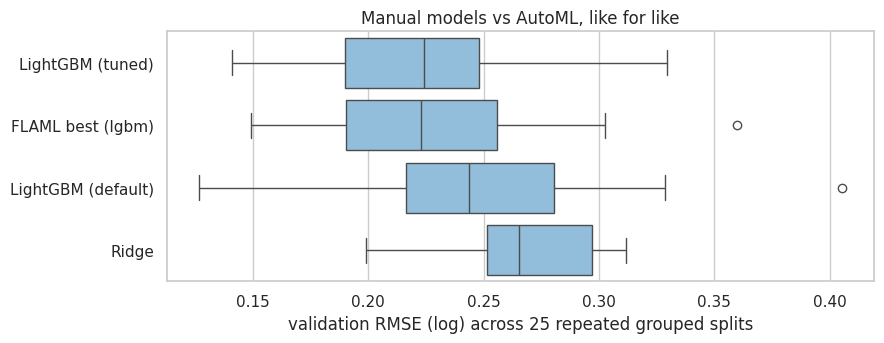

FLAML config minus tuned LightGBM (paired): mean +0.0049, FLAML better in 9/25


In [ ]:
# Re-score FLAML's best configuration inside MY pipeline, on the same 25 repeated grouped splits
flaml_pipe = Pipeline([("prep", make_preprocessor("tree")),
                       ("model", sklearn.base.clone(automl.model.estimator))])
cv = cross_validate(flaml_pipe, X_train_in, y_train, cv=RSPLITS, scoring="neg_root_mean_squared_error", n_jobs=-1)
rep_df[f"FLAML best ({automl.best_estimator})"] = -cv["test_score"]
summary = rep_df.agg(["mean", "std"]).T.round(4).sort_values("mean")
display(summary.rename(columns={"mean": "mean RMSE (25 splits)", "std": "sd"}))

fig, ax = plt.subplots(figsize=(9, 3.6))
sns.boxplot(data=rep_df[summary.index], orient="h", ax=ax, color="#85c1e9")
ax.set(xlabel="validation RMSE (log) across 25 repeated grouped splits", title="Manual models vs AutoML, like for like")
savefig("11_repeated_cv_comparison")
dd = rep_df[f"FLAML best ({automl.best_estimator})"] - rep_df["LightGBM (tuned)"]
print(f"FLAML config minus tuned LightGBM (paired): mean {dd.mean():+.4f}, FLAML better in {(dd < 0).sum()}/25")

**Interpretation and link to the manual models:**

- **FLAML's leaderboard agrees with the manual choice of model family.** On its own grouped CV with raw features, gradient-boosted trees lead: **LightGBM (0.211)** and XGBoost (0.216), ahead of Extra Trees (0.223) and Random Forest (0.260). This is the same ordering of model families as Section 9.
- **Like-for-like comparison:** FLAML's leaderboard number is not directly comparable with mine, because FLAML used different preprocessing and different folds. When FLAML's best configuration is re-scored inside my pipeline on the same 25 repeated splits:
  - it averages **0.228**, compared with **0.221** for my tuned LightGBM;
  - in the paired comparison FLAML's configuration is better in **13 of 25** splits, i.e. essentially a tie.
- **Conclusion:** AutoML **validates** the manual workflow (same model family, similar accuracy) rather than beating it. FLAML found a fairly different configuration (higher learning rate 0.06, fewer leaves, L1 regularisation), which suggests a broad region of good LightGBM settings rather than one sharp optimum.

**Limitations of AutoML here:**

1. **Results depend on the time budget and hardware.** FLAML searches for a fixed 120 seconds, so a faster or slower machine (e.g. Colab vs a laptop) can give a different best configuration or estimator. All other results in this notebook are deterministic.
2. **It optimises one number** and knows nothing about interpretability or leakage. It would have used the leaky emissions columns if I had not removed them (4.2).
3. **Validation design is my responsibility.** With FLAML's default random split it would validate on other years of the same countries and report misleadingly good scores. Preprocessing before FLAML would also have leaked across its folds, which is why raw features were passed.
4. **Less transparent.** Its search is less transparent than the manual one, which matters when the model must be explained.

The final model therefore remains the **manually tuned LightGBM**, which has the best repeated-CV evidence and a fully documented design.

## 12. Final evaluation on the held-out test set

**Final-model selection rule, set before looking at the test set:** use the model with the best grouped cross-validation evidence from Sections 9–11, i.e. the **tuned LightGBM**. The test set (39 unseen countries) is now used **once**; every model is refitted on the full training set and scored for comparison. The test results are reported, **not** used to change the choice, because picking whichever model happens to score best on 39 countries would make the reported score over-optimistic.

In [ ]:
BANDS = [0, 1, 5, 15, np.inf]                       # emissions bands (t per person), Section 3

def metrics(y_true_log, y_pred_log):
    t, p = np.expm1(y_true_log), np.expm1(y_pred_log)
    rmse_log = np.sqrt(mean_squared_error(y_true_log, y_pred_log))
    return {"rmse_log": rmse_log,
            "error_factor": np.exp(rmse_log),
            "r2_log": r2_score(y_true_log, y_pred_log),
            "rmse_tonnes": np.sqrt(mean_squared_error(t, p)),
            "mae_tonnes": mean_absolute_error(t, p),
            "median_abs_%_err": np.median(np.abs(p - t) / np.maximum(t, 0.01)) * 100,
            "band_accuracy": np.mean(np.digitize(t, BANDS) == np.digitize(p, BANDS))}

final_model = search.best_estimator_        # tuned LightGBM pipeline, refitted on all training data

test_models = {"Baseline (median)": candidates["Baseline (median)"], "Ridge": candidates["Ridge"],
               "Random Forest": candidates["Random Forest"], "LightGBM (default)": candidates["LightGBM"],
               f"FLAML config ({automl.best_estimator})": flaml_pipe}
test_preds, train_preds = {}, {}
for name, pipe in test_models.items():
    pipe.fit(X_train_in, y_train)
    test_preds[name], train_preds[name] = pipe.predict(X_test_in), pipe.predict(X_train_in)
test_preds["LightGBM (tuned) = FINAL"] = final_model.predict(X_test_in)
train_preds["LightGBM (tuned) = FINAL"] = final_model.predict(X_train_in)

test_results = pd.DataFrame({name: {**metrics(y_test, p),
                                    "train_rmse_log": np.sqrt(mean_squared_error(y_train, train_preds[name]))}
                             for name, p in test_preds.items()}).T
display(test_results.round(3))
FINAL = "LightGBM (tuned) = FINAL"
print(f"Final model: train RMSE {test_results.loc[FINAL, 'train_rmse_log']:.3f} | "
      f"CV RMSE {tuned_cv:.3f} | repeated-CV mean {rep_df['LightGBM (tuned)'].mean():.3f} | "
      f"test RMSE {test_results.loc[FINAL, 'rmse_log']:.3f}")

,rmse_log,error_factor,r2_log,rmse_tonnes,mae_tonnes,median_abs_%_err,band_accuracy,train_rmse_log
Baseline (median),0.818,2.266,-0.041,3.885,2.990,67.779,0.346,0.886
Ridge,0.250,1.284,0.903,1.373,0.906,25.203,0.756,0.191
Random Forest,0.200,1.222,0.938,1.675,0.820,17.019,0.862,0.017
LightGBM (default),0.186,1.205,0.946,1.152,0.706,16.627,0.884,0.017
FLAML config (lgbm),0.200,1.222,0.938,1.144,0.731,16.381,0.860,0.037
LightGBM (tuned) = FINAL,0.211,1.235,0.931,1.407,0.851,18.111,0.878,0.039


Final model: train RMSE 0.039 | CV RMSE 0.209 | repeated-CV mean 0.221 | test RMSE 0.211


**How to read these metrics:** `rmse_log` and `r2_log` are on the modelling (log) scale. `error_factor = exp(rmse_log)` means predictions are typically within that factor of the truth, in either direction (e.g. ×1.23 ⇒ +23% / −19%). `rmse_tonnes` and `mae_tonnes` are absolute errors and are dominated by the largest emitters. `median_abs_%_err` describes the typical country, and `band_accuracy` is the share of country-years placed in the correct emissions band (under 1, 1–5, 5–15, over 15 t).

In [ ]:
# Uncertainty from having only 39 test countries: country-level (cluster) bootstrap, 1,000 resamples
rng = np.random.default_rng(SEED)
test_countries = test_df["country_code"].values
uniq = np.unique(test_countries)
rows_by_c = {c: np.where(test_countries == c)[0] for c in uniq}
yt = y_test.values
boot = {m: [] for m in test_preds}
boot_band = {m: [] for m in test_preds}
for _ in range(1000):
    idx = np.concatenate([rows_by_c[c] for c in rng.choice(uniq, size=len(uniq), replace=True)])
    for m in test_preds:
        boot[m].append(np.sqrt(mean_squared_error(yt[idx], test_preds[m][idx])))
        boot_band[m].append(np.mean(np.digitize(np.expm1(yt[idx]), BANDS) == np.digitize(np.expm1(test_preds[m][idx]), BANDS)))
ci = pd.DataFrame({m: [np.percentile(boot[m], 2.5), np.median(boot[m]), np.percentile(boot[m], 97.5),
                       np.percentile(boot_band[m], 2.5), np.percentile(boot_band[m], 97.5)]
                   for m in test_preds},
                  index=["rmse_log 2.5%", "rmse_log median", "rmse_log 97.5%", "band_acc 2.5%", "band_acc 97.5%"]).T
display(ci.round(3))
diff = np.array(boot[FINAL]) - np.array(boot["LightGBM (default)"])
print("Tuned minus default test RMSE (paired bootstrap): 95%% CI [%.3f, %.3f]" % tuple(np.percentile(diff, [2.5, 97.5])))

,rmse_log 2.5%,rmse_log median,rmse_log 97.5%,band_acc 2.5%,band_acc 97.5%
Baseline (median),0.722,0.813,0.920,0.209,0.482
Ridge,0.197,0.249,0.300,0.664,0.836
Random Forest,0.155,0.200,0.241,0.795,0.919
LightGBM (default),0.147,0.186,0.220,0.823,0.939
FLAML config (lgbm),0.155,0.200,0.242,0.790,0.924
LightGBM (tuned) = FINAL,0.162,0.208,0.256,0.817,0.932


Tuned minus default test RMSE (paired bootstrap): 95% CI [0.005, 0.045]


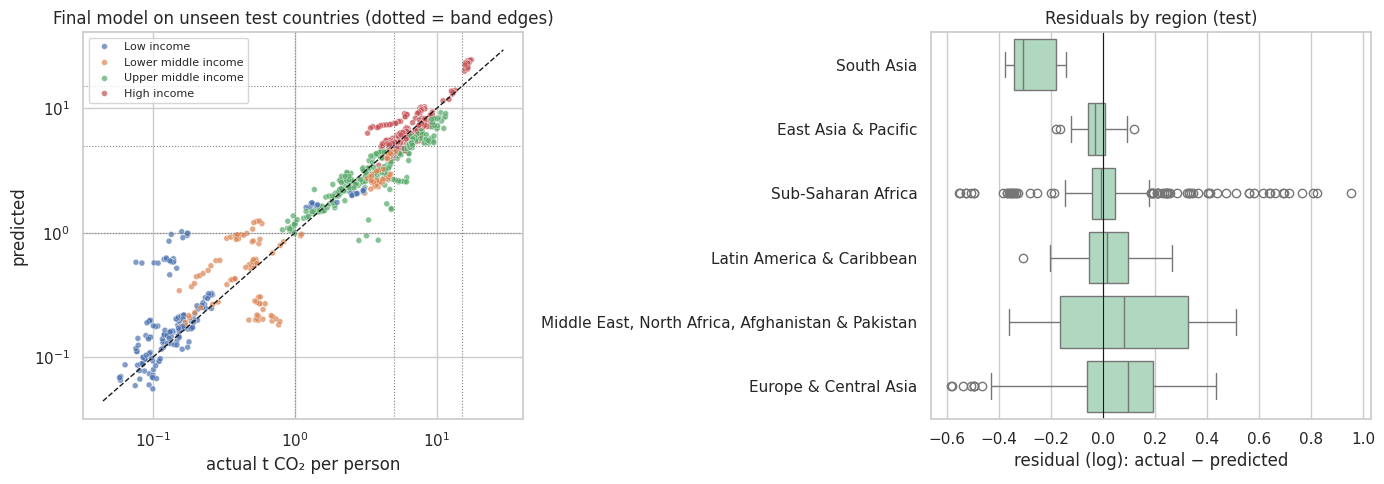

Test countries with the largest average errors:


,actual,predicted,mean_resid_log
country,,,
Equatorial Guinea,4.31,2.38,0.46
Sweden,4.76,7.63,-0.41
South Sudan,0.13,0.70,-0.40
Lebanon,4.02,2.57,0.34
Libya,8.30,5.70,0.33
Bangladesh,0.35,0.78,-0.27


In [ ]:
pred_final = test_preds[FINAL]
res_df = test_df.assign(pred=np.expm1(pred_final), resid_log=y_test.values - pred_final)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=res_df, x=TARGET, y="pred", hue="income_group", hue_order=INCOME_ORDER,
                s=18, alpha=0.7, ax=ax[0])
lims = [res_df[[TARGET, "pred"]].min().min() * 0.8, res_df[[TARGET, "pred"]].max().max() * 1.2]
ax[0].plot(lims, lims, "k--", lw=1); ax[0].set_xscale("log"); ax[0].set_yscale("log")
for b in BANDS[1:-1]:
    ax[0].axvline(b, color="grey", ls=":", lw=0.8); ax[0].axhline(b, color="grey", ls=":", lw=0.8)
ax[0].set(xlabel="actual t CO₂ per person", ylabel="predicted",
          title="Final model on unseen test countries (dotted = band edges)")
ax[0].legend(fontsize=8, title="")
reg_order = res_df.groupby("region")["resid_log"].median().sort_values().index
sns.boxplot(data=res_df, y="region", x="resid_log", order=reg_order, ax=ax[1], color="#a9dfbf")
ax[1].axvline(0, color="k", lw=0.8)
ax[1].set(xlabel="residual (log): actual − predicted", ylabel="", title="Residuals by region (test)")
savefig("12_test_predictions_residuals")

worst = (res_df.groupby("country")
         .agg(actual=(TARGET, "mean"), predicted=("pred", "mean"), mean_resid_log=("resid_log", "mean"))
         .assign(abs_err=lambda d: d["mean_resid_log"].abs())
         .sort_values("abs_err", ascending=False).drop(columns="abs_err"))
print("Test countries with the largest average errors:")
display(worst.head(6).round(2))

**Interpretation of the test results (39 unseen countries):**

**1. Against the success criteria set in Section 3, the final model passes all of them:**

| Criterion | Target | Final model (95% bootstrap interval) |
|---|---|---|
| Beat the baseline | clearly | RMSE 0.21 vs 0.82 |
| Typical error factor | ≤ ×1.30 | **×1.24** (RMSE 0.211; interval 0.16–0.26) |
| R² (log scale) | ≥ 0.80 | **0.93** |
| Band accuracy | ≥ 80% | **88%** (82–93%) |
| CV and test consistent | within uncertainty | test 0.211 vs single-split CV 0.209 and repeated-CV mean 0.221 |

**2. How the different metrics read:**

- **Log scale:** the error factor of ×1.24 means a typical prediction is within roughly +24% / −19% of the truth.
- **Median country:** the median absolute error is about **18%**.
- **In tonnes:** the MAE is **0.85 t** and the RMSE **1.4 t**. These are larger because a few high emitters, where the same *relative* error means many tonnes, dominate absolute errors. They are reported for completeness, but the model was not optimised for them.

**3. The default model scored better on this test set, and the final model is still the tuned one.**

- The default LightGBM scored better on the test set (RMSE 0.186 vs 0.211; band accuracy 88% for both). The paired bootstrap interval for the difference, [+0.005, +0.045], suggests that on *these* 39 countries the default model really was better.
- **Why the selection is not changed:** the selection rule was fixed in advance on cross-validation evidence. Section 10.1 showed the tuned model was better in 19 of 25 repeated splits, but not in all, and the test set is one more draw from that distribution. Switching to whichever model scores best on the test set would make the reported test score over-optimistic.
- **What the evidence supports:** the tuned model is the better choice *on balance*. It is **not** shown to be better for every sample of countries, and the size of the tuning gain is uncertain.

**4. Where the model goes wrong:**

- The largest errors are for countries whose energy profile is unusual for their income or region: **Equatorial Guinea** and **Libya** (oil and gas producers, under-predicted), **Sweden** (high income but low-carbon electricity, over-predicted) and **South Sudan** (very sparse data).
- The residuals by region show over-prediction for South Asia (only Bangladesh in the test set) and the widest spread for the Middle East & North Africa.
- These are cases where a country departs from the typical pattern linking development and energy use to emissions.

## 13. Explainable AI (XAI)

LightGBM is a "black-box" ensemble, so I use **post-hoc** XAI to open it up, at two levels:

- **Global** (how the model behaves across all countries): SHAP summary plots, SHAP dependence plots, PDP/ICE and ALE curves, and permutation importance.
- **Local** (why the model made *one* prediction): SHAP waterfall plots and LIME.

I then **cross-check** the methods against each other. Agreement between methods **raises confidence but does not prove an explanation is correct**: all of them explain the *same* model, which learned from the *same* correlated data. They tell us what the model has learned, not how the world works.

All explanations are of the final tuned LightGBM, on the **test countries** (data the model never saw). Values are on the model's **log1p scale**: a SHAP value of +0.3 means the feature pushes the prediction up by about 35% (e^0.3 ≈ 1.35) relative to the average.

In [ ]:
prep_f = final_model.named_steps["prep"]
reg = final_model.named_steps["model"]
Xtr_f = prep_f.transform(X_train_in)
Xte_f = prep_f.transform(X_test_in)

explainer = shap.TreeExplainer(reg)
sv = explainer(Xte_f)

# Additivity check: base value + sum of SHAP values = model prediction
recon = sv.base_values + sv.values.sum(axis=1)
print("Max |reconstruction - prediction|: %.2e" % np.abs(recon - reg.predict(Xte_f)).max())
print("Base value (average prediction): %.3f log -> %.2f t CO2 per person"
      % (np.ravel(sv.base_values)[0], np.expm1(np.ravel(sv.base_values)[0])))

Max |reconstruction - prediction|: 8.44e-15
Base value (average prediction): 1.263 log -> 2.54 t CO2 per person


### 13.1 Global explanation: SHAP summary

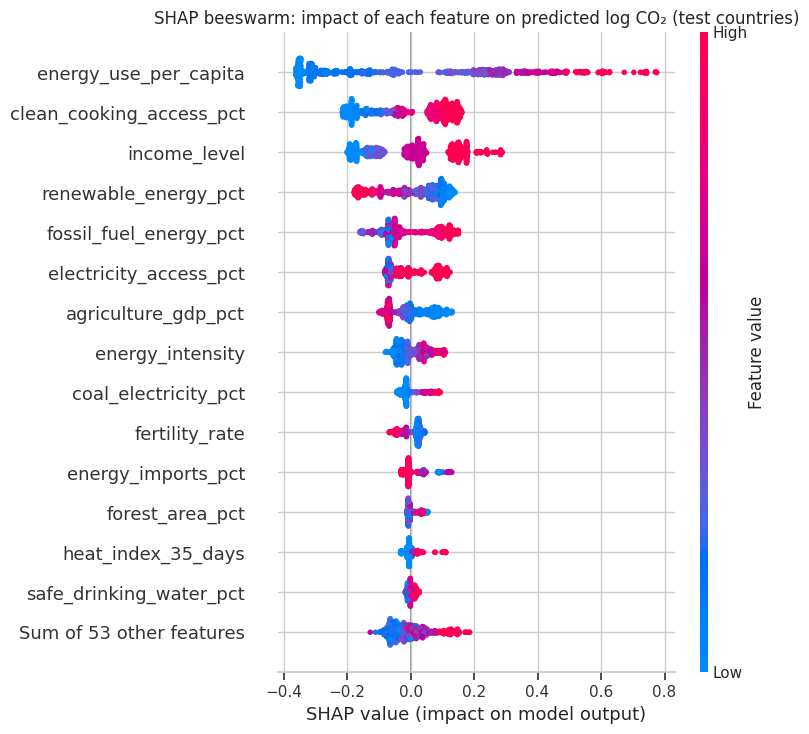

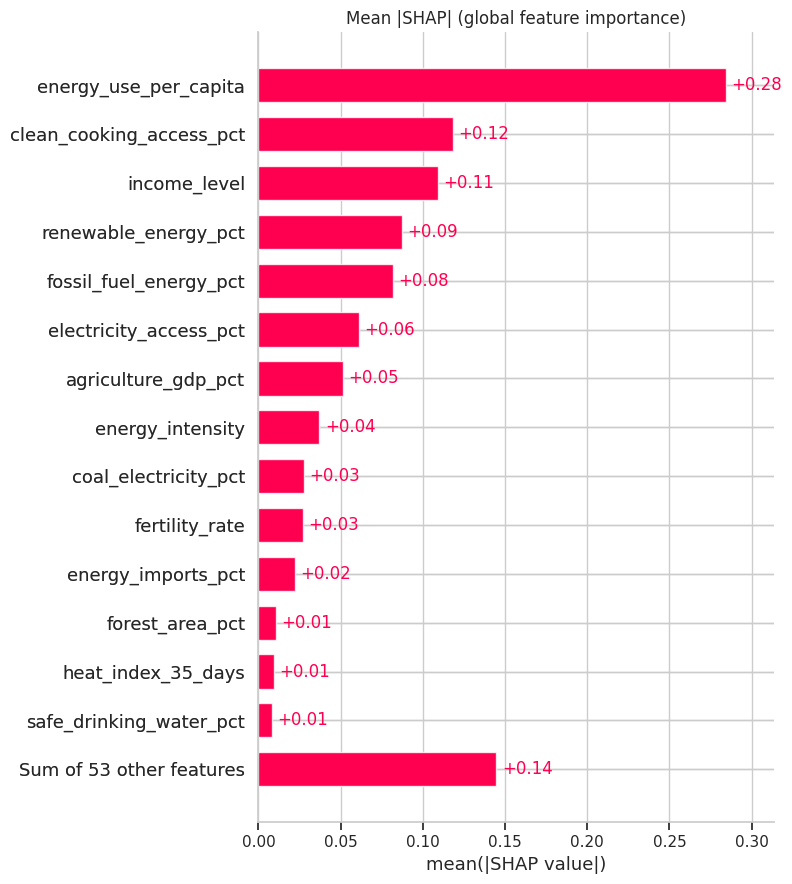

,mean |SHAP|
energy_use_per_capita,0.2845
clean_cooking_access_pct,0.1185
income_level,0.1090
renewable_energy_pct,0.0871
fossil_fuel_energy_pct,0.0819
electricity_access_pct,0.0612
agriculture_gdp_pct,0.0512
energy_intensity,0.0371
coal_electricity_pct,0.0278
fertility_rate,0.0268


In [ ]:
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("SHAP beeswarm: impact of each feature on predicted log CO₂ (test countries)")
savefig("13_shap_beeswarm")

shap.plots.bar(sv, max_display=15, show=False)
plt.title("Mean |SHAP| (global feature importance)")
savefig("13_shap_bar")

shap_imp = pd.Series(np.abs(sv.values).mean(axis=0), index=Xte_f.columns).sort_values(ascending=False)
display(shap_imp.head(10).round(4).to_frame("mean |SHAP|"))

**Interpretation of the global SHAP explanation (what the *model* relies on):**

1. **`energy_use_per_capita` has by far the largest influence on predictions** (mean |SHAP| ≈ 0.28, more than twice the next one). In the beeswarm, high energy use (red) raises predictions by as much as +0.75 on the log scale (about ×2.1 relative to the average). Low energy use lowers them by about 0.35 (about ×0.70). This matches the physical link between fossil energy and CO₂.
2. **Development-related features come next:** `clean_cooking_access_pct`, `income_level` and `electricity_access_pct`. The model predicts much lower emissions for countries where households still cook with wood or charcoal and incomes are low.
3. **Energy-mix features have their own effect:** a high `renewable_energy_pct` (red) lowers predictions and a high `fossil_fuel_energy_pct` raises them, followed by `energy_intensity` and `coal_electricity_pct`. In the model, two countries with similar energy use but different energy mixes receive different predictions.
4. **Economic structure:** a large agricultural share of GDP is associated with lower predictions.

Climate (heat-index days) and governance indicators have only small SHAP values once energy and development are in the model. Because many features are correlated, a small individual SHAP value does not mean a feature is unrelated to emissions; its information may be carried by a correlated feature (see 13.1b).

### 13.1b Grouped SHAP: importance of *groups* of correlated features

Because many features are strongly correlated (Section 6.6), the model can give credit to any one of several near-duplicates, so **individual** ranks can be unstable. SHAP values are additive, so I add them up within groups of related features for each country-year and then average the absolute group total. Group importance is much less sensitive to how credit is split *within* a group.

,mean |group SHAP|,n features,share of total
Energy use & mix,0.351,7,0.463
Energy access,0.160,2,0.211
Income & economic structure,0.149,11,0.196
"Health, education & society",0.049,22,0.065
Governance,0.024,6,0.031
Climate & land,0.019,11,0.025
Region & year,0.006,8,0.008


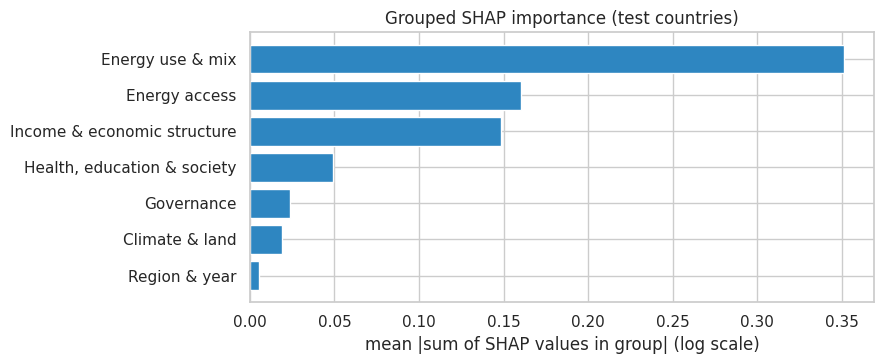

In [ ]:
GROUPS = {
    "Energy use & mix": ["energy_use_per_capita", "fossil_fuel_energy_pct", "renewable_energy_pct",
                         "renewable_electricity_pct", "coal_electricity_pct", "energy_intensity", "energy_imports_pct"],
    "Energy access": ["electricity_access_pct", "clean_cooking_access_pct"],
    "Income & economic structure": ["income_level", "gdp_growth", "agriculture_gdp_pct", "forest_depletion_gni_pct",
                                    "resource_depletion_gni_pct", "food_production_index", "unemployment_pct",
                                    "labour_force_participation", "journal_articles", "patent_applications",
                                    "rnd_spend_gdp_pct"],
    "Governance": ["control_of_corruption", "government_effectiveness", "political_stability",
                   "regulatory_quality", "rule_of_law", "voice_accountability", "legal_rights_index"],
    "Climate & land": ["cooling_degree_days", "heating_degree_days", "heat_index_35_days", "land_surface_temp",
                       "drought_index_spei", "pm25_exposure", "agricultural_land_pct", "forest_area_pct",
                       "tree_cover_loss_ha", "water_stress_pct", "freshwater_withdrawal_pct", "protected_areas_pct"],
}
def group_of(col):
    if col.startswith("region_") or col == "year":
        return "Region & year"
    for g, cols in GROUPS.items():
        if col in cols:
            return g
    return "Health, education & society"

col_group = pd.Series({c: group_of(c) for c in Xte_f.columns})
sv_df = pd.DataFrame(sv.values, columns=Xte_f.columns)
group_sv = sv_df.T.groupby(col_group).sum().T                 # summed SHAP per group, per country-year
group_imp = group_sv.abs().mean().sort_values(ascending=False)
summary_g = pd.DataFrame({"mean |group SHAP|": group_imp,
                          "n features": col_group.value_counts().reindex(group_imp.index),
                          "share of total": group_imp / group_imp.sum()})
display(summary_g.round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(group_imp.index[::-1], group_imp.values[::-1], color="#2e86c1")
ax.set(xlabel="mean |sum of SHAP values in group| (log scale)", title="Grouped SHAP importance (test countries)")
savefig("13_shap_grouped")

**Interpretation: grouping confirms the picture and makes it more robust.**

- **Energy use & mix** accounts for **~46%** of the total grouped SHAP importance, **energy access** (electricity and clean cooking) for **~21%**, and **income & economic structure** for **~20%**. Together these three groups account for almost 90% of the model's reliance on its inputs.
- **Health, education & society** contributes only **~6.5%** although it has the most features (22). Many of these features are correlated with income and energy access, so the model gets the same information from those groups instead. This does **not** mean health or education are unrelated to emissions (life expectancy has ρ ≈ 0.77 with log emissions, 6.4), only that the model does not *need* them once energy and income are known.
- **Governance (~3%), climate & land (~2.5%) and region/year (<1%)** add little on top of the other groups.

Because group totals do not depend on how credit is divided *within* a group, these shares are more trustworthy than the exact ranking of individual correlated features.

### 13.2 SHAP dependence plots: *how* each top feature acts

Each dot is one test country-year. The x-axis is the feature value, the y-axis is its SHAP value, and the colour is the feature SHAP finds it interacts with most.

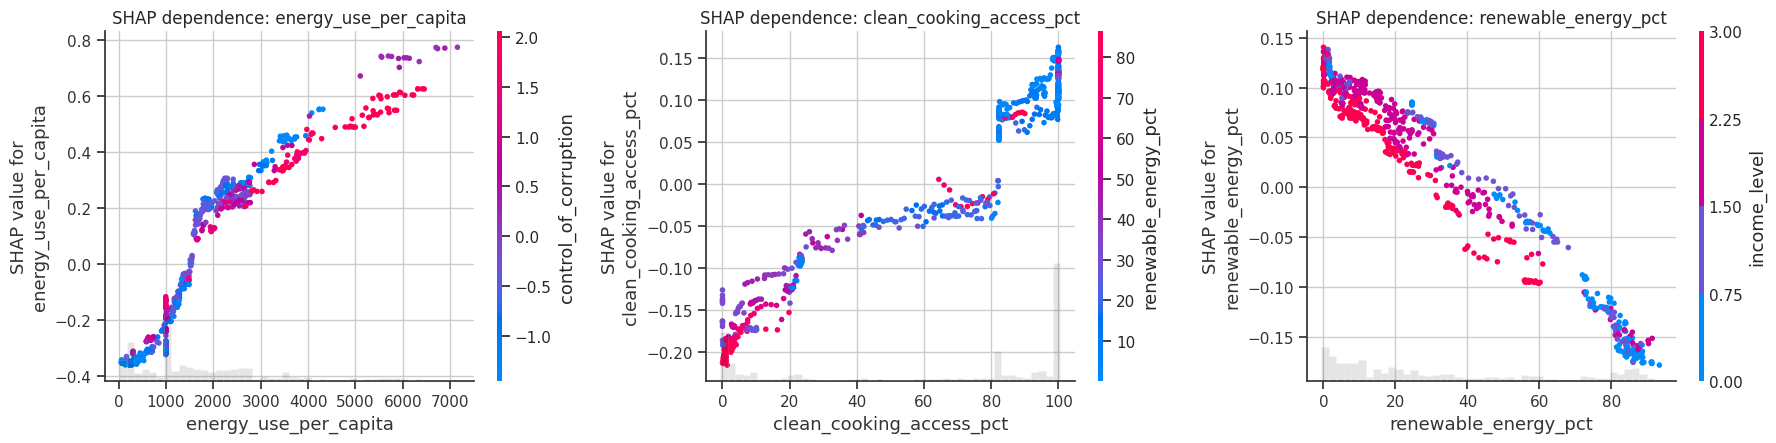

In [ ]:
TOP_NUM = [f for f in shap_imp.index if f in ALL_NUM_FEATURES][:3]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for ax, f in zip(axes, TOP_NUM):
    shap.plots.scatter(sv[:, f], color=sv, ax=ax, show=False)
    ax.set_title(f"SHAP dependence: {f}")
    if Xte_f[f].max() > 50 * max(Xte_f[f].median(), 1e-9):
        ax.set_xscale("symlog")
savefig("13_shap_dependence")

**Interpretation of the dependence plots (how the model's predictions respond):**

- **Energy use:** the SHAP value rises very steeply up to about 2,000 kg oil-equivalent per person, then more gradually. The model therefore treats differences among low-energy countries as more important than the same absolute difference among high-energy countries. This is a *non-linear* response, which helps explain why LightGBM outperformed Ridge.
- **Clean-cooking access** behaves like a **threshold** in the model: there is a clear jump near 80–100% access, the range where households in the data move from biomass to electricity and gas.
- **Renewable share** has an almost linear negative relationship with the SHAP value: across the observed range (~0% to ~90%), its contribution falls by about 0.3 (≈ −25%), given the other features. The colouring shows that at a given renewable share, **high-income countries** (red) tend to have lower SHAP values. The model seems to treat a high renewable share differently in rich countries (hydro, wind) than in poor ones (biomass), which is consistent with the compositional point in 6.4.

These plots describe how the model's predictions change with each feature; they do not show what would happen if a country actually changed that feature.

### 13.3 PDP/ICE and ALE: average effects, checked for correlated features

**PDP** (with **ICE** lines for individual countries) shows how the average prediction changes when one feature is varied. Because PDP holds all other features fixed, it can create unrealistic combinations when features are correlated, and Section 6.6 showed strong correlations. **ALE** avoids this by using only local changes within the observed data. If PDP and ALE agree, confidence increases.

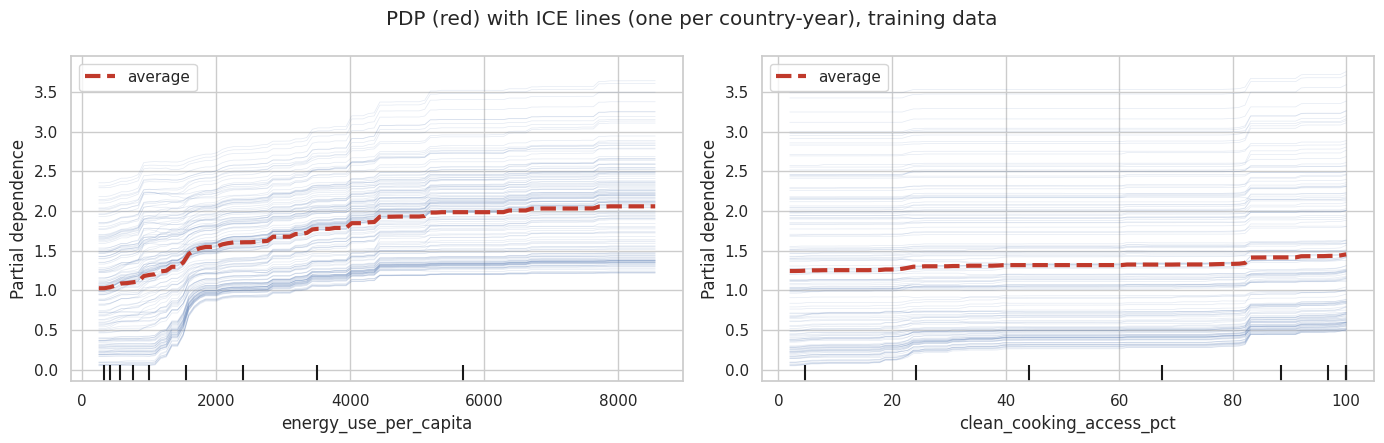

In [ ]:
PD_FEATS = TOP_NUM[:2]
X_pdp = X_train_in.dropna(subset=PD_FEATS)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
PartialDependenceDisplay.from_estimator(final_model, X_pdp, features=PD_FEATS, kind="both",
                                        subsample=150, random_state=SEED, ax=ax,
                                        ice_lines_kw={"alpha": 0.15}, pd_line_kw={"color": "#c0392b", "lw": 3})
fig.suptitle("PDP (red) with ICE lines (one per country-year), training data")
savefig("13_pdp_ice")

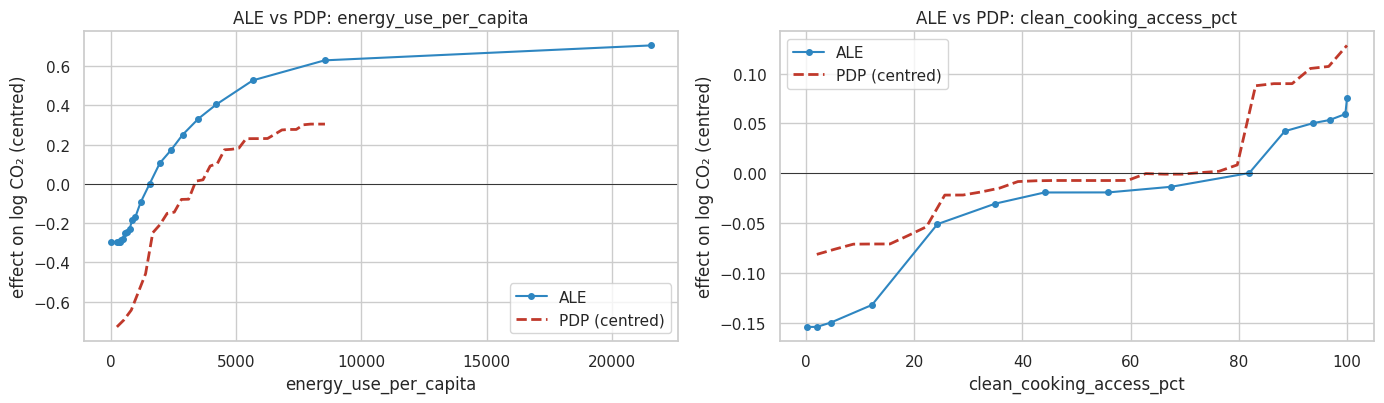

In [ ]:
def ale_1d(model, X, feature, n_bins=20):
    # First-order ALE (Apley & Zhu, 2020).
    Xv = X[X[feature].notna()]
    x = Xv[feature].values
    edges = np.unique(np.quantile(x, np.linspace(0, 1, n_bins + 1)))
    idx = np.clip(np.searchsorted(edges, x, side="right") - 1, 0, len(edges) - 2)
    lo, hi = Xv.copy(), Xv.copy()
    lo[feature], hi[feature] = edges[idx], edges[idx + 1]
    diff = model.predict(hi) - model.predict(lo)                       # local effect in each bin
    nb = len(edges) - 1
    mean_diff = pd.Series(diff).groupby(idx).mean().reindex(range(nb), fill_value=0).values
    counts = np.bincount(idx, minlength=nb)
    ale = np.concatenate([[0], np.cumsum(mean_diff)])                  # accumulate
    centres = (ale[:-1] + ale[1:]) / 2
    return edges, ale - np.average(centres, weights=counts)            # centre on 0

from sklearn.inspection import partial_dependence
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, f in zip(axes, PD_FEATS):
    edges, ale = ale_1d(final_model, X_pdp, f)
    pd_res = partial_dependence(final_model, X_pdp, [f], grid_resolution=30)
    grid = (pd_res["grid_values"] if "grid_values" in pd_res else pd_res["values"])[0]
    pdp = pd_res["average"][0]
    ax.plot(edges, ale, "o-", color="#2e86c1", ms=4, label="ALE")
    ax.plot(grid, pdp - pdp.mean(), "--", color="#c0392b", lw=2, label="PDP (centred)")
    ax.axhline(0, color="k", lw=0.6)
    ax.set(title=f"ALE vs PDP: {f}", xlabel=f, ylabel="effect on log CO₂ (centred)")
    if X_pdp[f].max() > 50 * max(X_pdp[f].median(), 1e-9):
        ax.set_xscale("symlog")
    ax.legend()
savefig("13_ale_vs_pdp")

**Interpretation: PDP, ICE and ALE give a consistent description of the model.**

- **Same direction, shape and size:** predicted emissions rise steeply with energy use up to ~2,000 kg and then more slowly, flattening above ~6,000 kg. Over the common range the total effect is about 1 unit on the log scale in both methods (roughly a ×2.7 difference in predictions). Clean-cooking access shows a step near 80% in both.
- **ICE lines are mostly parallel:** the model's response to energy use is similar across countries; they differ mainly in their *starting level*, which is set by the other features.
- **Why this agreement matters:** energy use is strongly correlated with income, electricity access and life expectancy (Section 6.6). PDP therefore evaluates unrealistic combinations, e.g. a very poor country given Norway's energy use. ALE avoids this by using only local changes within each bin of real countries. Since both methods agree, the curve is unlikely to be an artefact of those unrealistic combinations, which is the standard check when features are correlated.
- **The small differences** are at the extremes (very low energy use and very high cooking access), where PDP extrapolates most and fewer real countries exist. There the ALE curve is the more trustworthy description.

Both PDP and ALE describe the **model's** average response under their own assumptions. They are not estimates of the real-world effect of changing a country's energy use.

### 13.4 Permutation importance (model-agnostic check)

Permutation importance shuffles one **raw** input column at a time on the **test set** and measures how much the test RMSE gets worse. Unlike SHAP, it does not look inside the model at all, so it is an independent check.

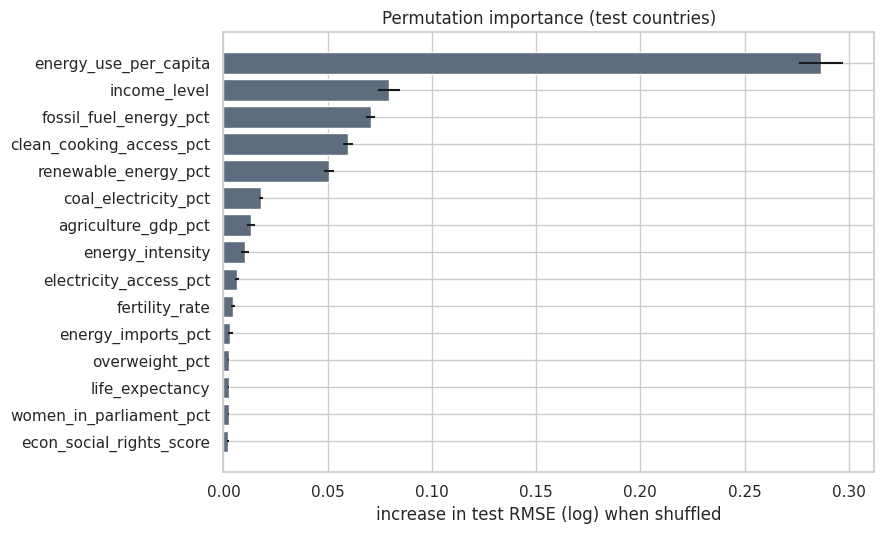

In [ ]:
perm = permutation_importance(final_model, X_test_in, y_test, scoring="neg_root_mean_squared_error",
                              n_repeats=10, random_state=SEED, n_jobs=-1)
perm_imp = (pd.DataFrame({"importance": perm.importances_mean, "std": perm.importances_std},
                         index=X_test_in.columns).sort_values("importance", ascending=False))
top_p = perm_imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top_p.index, top_p["importance"], xerr=top_p["std"], color="#5d6d7e")
ax.set(xlabel="increase in test RMSE (log) when shuffled", title="Permutation importance (test countries)")
savefig("13_permutation_importance")

### 13.5 Local explanations: why did the model predict *this* country's emissions?

I explain three test countries in 2020: the **highest** predicted emitter, a **middle** one and the **lowest**. The SHAP waterfall starts from the average prediction (base value) and adds each feature's contribution until it reaches the prediction for that country.

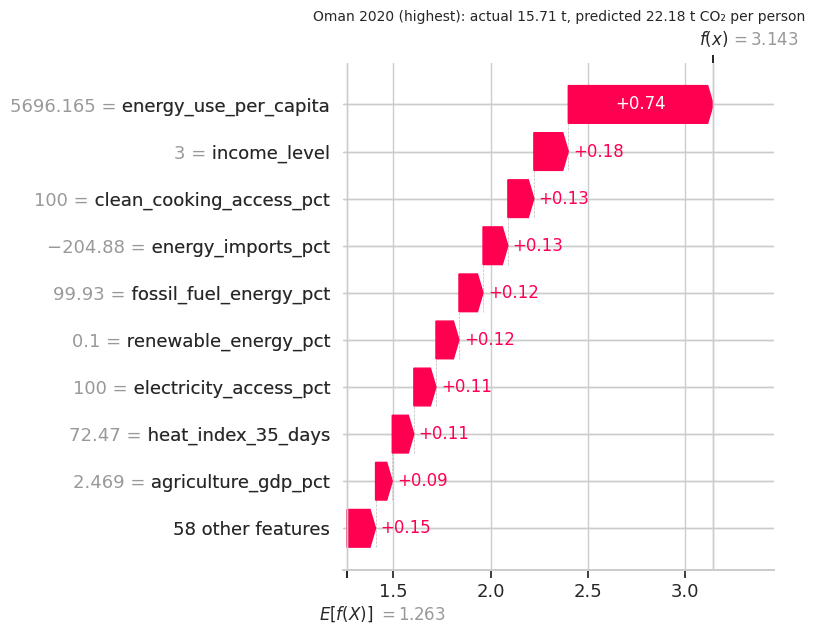

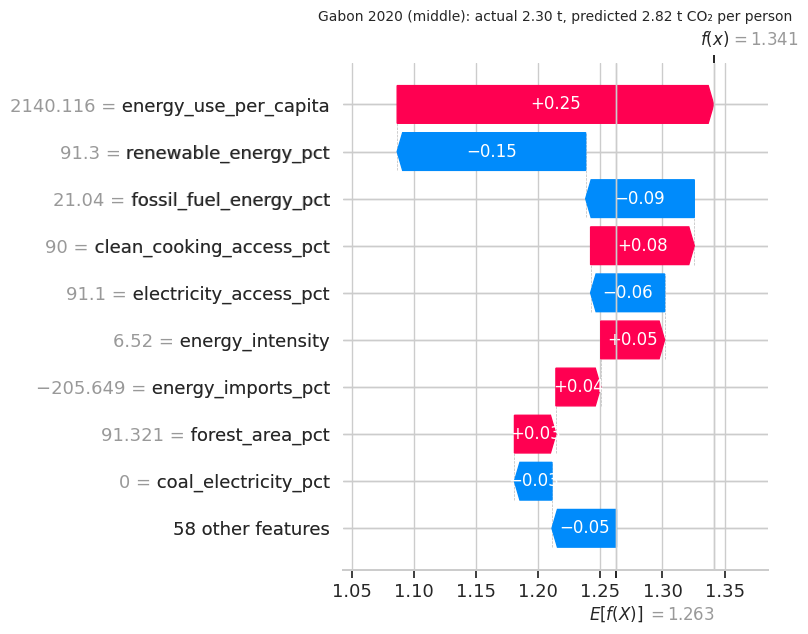

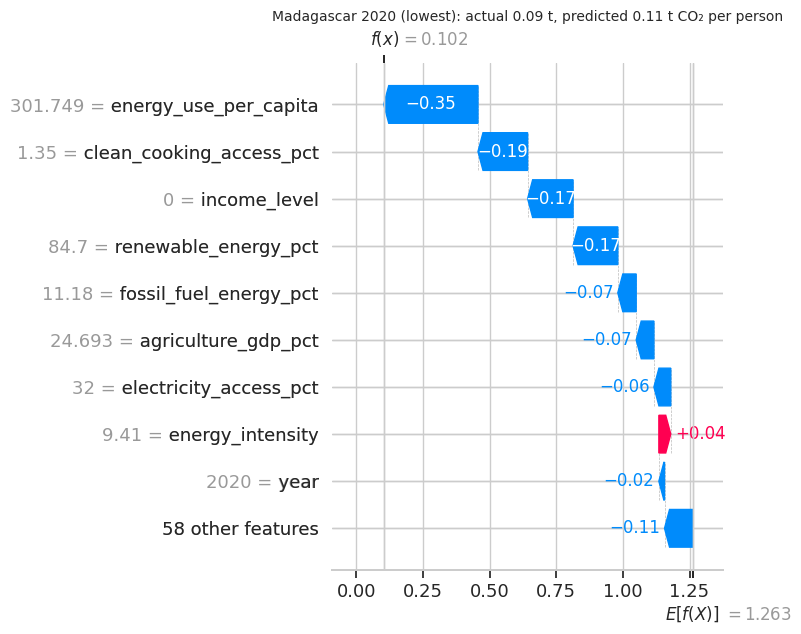

In [ ]:
latest = test_df["year"].max()
mask = (test_df["year"] == latest).values
pos = np.where(mask)[0]
order_ = pos[np.argsort(pred_final[mask])]
LOCAL = {"highest": order_[-1], "middle": order_[len(order_) // 2], "lowest": order_[0]}

for label, i in LOCAL.items():
    row = test_df.iloc[i]
    shap.plots.waterfall(sv[i], max_display=10, show=False)
    plt.title(f"{row['country']} {int(row['year'])} ({label}): actual {row[TARGET]:.2f} t, "
              f"predicted {np.expm1(pred_final[i]):.2f} t CO₂ per person", fontsize=10)
    savefig(f"13_shap_waterfall_{label}")

**Interpretation of the local (SHAP waterfall) explanations:**

- **Oman 2020 (highest predicted, 22.2 t vs actual 15.7 t):**
  - Very high energy use contributes +0.74 (about ×2.1).
  - Smaller contributions come from high income, almost 100% fossil energy, ~0% renewables and being a large energy *exporter* (negative energy imports).
  - The model **over-predicts** Oman. A plausible reason is that Oman's feature profile resembles the very high emitters in the training data (Qatar, Kuwait, Bahrain), while its actual emissions are lower than theirs.
- **Gabon 2020 (middle, 2.8 t vs actual 2.3 t):**
  - This is an example of features pulling in **opposite directions**. Moderately high energy use (+0.25) and good cooking-fuel access (+0.08) push the prediction up.
  - A **91% renewable** energy share (−0.15) and a low fossil share (−0.09) pull it down, so the prediction ends up close to the average.
- **Madagascar 2020 (lowest, 0.11 t vs actual 0.09 t):**
  - Almost every feature lowers the prediction: very low energy use (−0.35), almost no clean-cooking access (−0.19), low income (−0.17) and a high (mostly biomass) renewable share (−0.17).
  - The prediction is very close to the actual value.

These local explanations show *why the model* gives two countries of similar income different predictions, which a single global ranking cannot show. They describe the model's reasoning, not verified causes of each country's emissions.

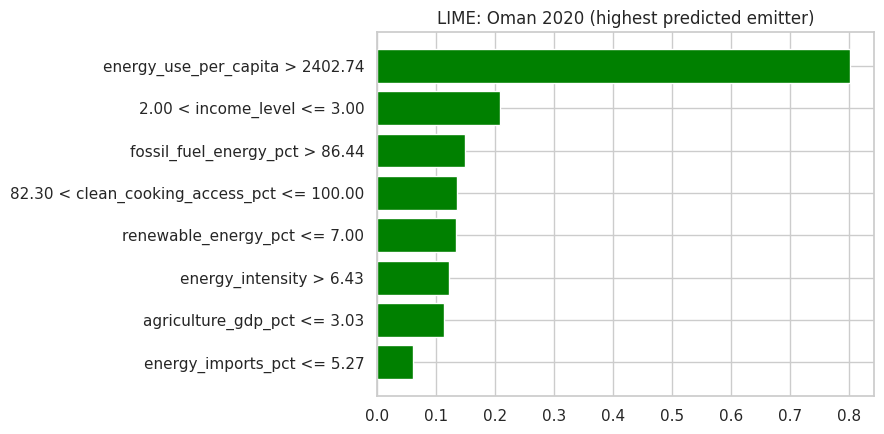

,LIME rule,LIME weight,SHAP value (same feature)
0,energy_use_per_capita > 2402.74,0.802,0.744
1,2.00 < income_level <= 3.00,0.208,0.177
2,fossil_fuel_energy_pct > 86.44,0.149,0.123
3,82.30 < clean_cooking_access_pct <= 100.00,0.135,0.133
4,renewable_energy_pct <= 7.00,0.134,0.118
5,energy_intensity > 6.43,0.121,0.064
6,agriculture_gdp_pct <= 3.03,0.113,0.086
7,energy_imports_pct <= 5.27,0.061,0.128


In [ ]:
lime_explainer = LimeTabularExplainer(Xtr_f.values, feature_names=list(Xtr_f.columns), mode="regression",
                                      discretize_continuous=True, random_state=SEED)
predict_fn = lambda a: reg.predict(pd.DataFrame(a, columns=Xtr_f.columns))

i = LOCAL["highest"]
lime_exp = lime_explainer.explain_instance(Xte_f.values[i], predict_fn, num_features=8, num_samples=3000)
fig = lime_exp.as_pyplot_figure()
fig.set_size_inches(9, 4.5)
plt.title(f"LIME: {test_df.iloc[i]['country']} {int(test_df.iloc[i]['year'])} (highest predicted emitter)")
savefig("13_lime_highest")

shap_row = pd.Series(sv.values[i], index=Xte_f.columns)
lime_idx = [j for j, _ in lime_exp.local_exp[1]]       # label 1 = the regression output; same order as as_list()
lime_feats = [Xtr_f.columns[j] for j in lime_idx]
compare_local = pd.DataFrame({"LIME rule": [r for r, _ in lime_exp.as_list()],
                              "LIME weight": [w for _, w in lime_exp.as_list()],
                              "SHAP value (same feature)": [shap_row.get(f, np.nan) for f in lime_feats]})
display(compare_local.round(3))

In [ ]:
# LIME stability: the same explanation repeated with 10 different random seeds
runs = []
for seed in range(10):
    le = LimeTabularExplainer(Xtr_f.values, feature_names=list(Xtr_f.columns), mode="regression",
                              discretize_continuous=True, random_state=seed)
    ex = le.explain_instance(Xte_f.values[i], predict_fn, num_features=8, num_samples=3000)
    for rank, (j, w) in enumerate(ex.local_exp[1], 1):
        runs.append({"seed": seed, "feature": Xtr_f.columns[j], "weight": w, "rank": rank})
runs = pd.DataFrame(runs)
stab = (runs.groupby("feature")
        .agg(times_in_top8=("seed", "nunique"), mean_weight=("weight", "mean"), sd_weight=("weight", "std"),
             best_rank=("rank", "min"), worst_rank=("rank", "max"))
        .assign(shap_value=lambda d: [shap_row.get(f, np.nan) for f in d.index])
        .sort_values("mean_weight", key=np.abs, ascending=False))
display(stab.round(3))
print(f"{(stab['times_in_top8'] == 10).sum()} features appear in the top 8 in all 10 runs; "
      f"{(stab['times_in_top8'] < 10).sum()} appear only in some runs")

,times_in_top8,mean_weight,sd_weight,best_rank,worst_rank,shap_value
feature,,,,,,
energy_use_per_capita,10,0.791,0.007,1,1,0.744
income_level,10,0.204,0.009,2,2,0.177
fossil_fuel_energy_pct,10,0.150,0.008,3,3,0.123
renewable_energy_pct,10,0.133,0.008,4,6,0.118
clean_cooking_access_pct,10,0.132,0.005,4,5,0.133
agriculture_gdp_pct,10,0.116,0.009,5,7,0.086
energy_intensity,10,0.108,0.009,6,7,0.064
energy_imports_pct,3,0.058,0.001,8,8,0.128
electricity_access_pct,6,0.057,0.006,8,8,0.114


7 features appear in the top 8 in all 10 runs; 3 appear only in some runs


**Interpretation: LIME agrees with SHAP for Oman, and its main conclusions are stable.**

- **Agreement with SHAP:** LIME fits a simple linear model to random perturbations around this one country. Its top rule is the same as SHAP's (energy use above ~2,400 kg, weight ≈ 0.80 vs SHAP 0.74), followed by high income, a fossil share above 86% and low renewables, with weights of similar size to the SHAP values.
- **Stability across 10 random seeds:**
  - the **top three features and their order never change**, and the 7 most important features appear in all 10 runs, with very small variation in weight (sd < 0.01);
  - the **8th feature changes between runs** (electricity access, energy imports or coal share). This is LIME's sampling noise: features with small effects are not reliably ranked.
  - The one clear disagreement with SHAP is `energy_imports_pct`: SHAP gives it +0.13, but LIME usually leaves it out of the top 8.

**Conclusion:** LIME is a useful **sanity check** for the strongest effects in one explanation. Its weights depend on the random neighbourhood and the binning, so it is not used as the main explanation, and agreement for one country does not validate it for others.

### 13.6 Cross-checking the methods

Do SHAP, permutation importance and LightGBM's built-in (split-gain) importance rank the features the same way? The one-hot region columns are summed into one `region` feature so that all three methods are compared on the same raw inputs.

In [ ]:
def to_raw(s):
    s = s.copy()
    reg_cols = [c for c in s.index if c.startswith("region_")]
    s["region"] = s[reg_cols].sum(); s = s.drop(reg_cols)
    return s

gain = pd.Series(reg.booster_.feature_importance(importance_type="gain"), index=Xtr_f.columns)
cross = pd.DataFrame({"SHAP": to_raw(shap_imp), "Permutation": perm_imp["importance"], "LGBM gain": to_raw(gain)})
cross = cross.fillna(0)          # sparse columns dropped by the pipeline have zero SHAP / gain
ranks = cross.rank(ascending=False).astype(int)
top_union = ranks[(ranks <= 10).any(axis=1)].sort_values("SHAP")
display(top_union.rename(columns=lambda c: c + " rank"))

top15 = ranks[(ranks <= 15).any(axis=1)].index
print(f"Rank agreement (Spearman) on the {len(top15)} features in any method's top 15 | on all {len(cross)} features:")
for a, b in [("SHAP", "Permutation"), ("SHAP", "LGBM gain"), ("Permutation", "LGBM gain")]:
    r_top = spearmanr(cross.loc[top15, a], cross.loc[top15, b]).statistic
    r_all = spearmanr(cross[a], cross[b]).statistic
    print(f"  {a:11s} vs {b:11s}: {r_top:.2f} | {r_all:.2f}")
print("Features with negative permutation importance (shuffling them did not hurt):",
      int((cross["Permutation"] <= 0).sum()))

,SHAP rank,Permutation rank,LGBM gain rank
energy_use_per_capita,1,1,1
clean_cooking_access_pct,2,4,2
income_level,3,2,3
renewable_energy_pct,4,5,5
fossil_fuel_energy_pct,5,3,7
electricity_access_pct,6,9,4
agriculture_gdp_pct,7,7,6
energy_intensity,8,8,9
coal_electricity_pct,9,6,13
fertility_rate,10,10,8


Rank agreement (Spearman) on the 21 features in any method's top 15 | on all 70 features:
  SHAP        vs Permutation: 0.80 | 0.43
  SHAP        vs LGBM gain  : 0.92 | 0.94
  Permutation vs LGBM gain  : 0.78 | 0.43
Features with negative permutation importance (shuffling them did not hurt): 35


**Interpretation: the methods agree on what matters most to the model.**

- **The top feature is the same in all three methods:** energy use per person ranks **1st** in SHAP, permutation importance and LightGBM gain.
- **The next group is the same, in slightly different orders:** income level, clean-cooking access, fossil-fuel share and renewable share.
- **High agreement where it matters:** on the 21 features that are in any method's top 15, rank agreement is high (Spearman **0.80** SHAP vs permutation, **0.92** SHAP vs gain).
- **Low agreement on the rest is expected:** agreement across *all* 70 inputs is lower (~0.4). The bottom features have essentially zero importance in every method: 35 inputs, including the sparse columns the pipeline drops, have zero or negative permutation importance. Their exact ranks are therefore random noise.
- **Where the methods differ, the reason is understandable:** `electricity_access_pct` ranks higher in SHAP and gain (6th, 4th) than in permutation importance (9th). It is strongly correlated with clean-cooking access and income, so when it is shuffled the model can recover much of the same information from those features.

**What this does and does not show:** the agreement shows that the ranking is a **stable description of this model**, not an artefact of one method. It does not prove that these features are the true causes of emissions, because all methods explain the same model trained on the same correlated data. In practice, about 10 features carry nearly all the predictive information, so a simpler model on these alone could be explored.

### 13.7 Limitations of these explanations

- **Association, not causation.** SHAP, PDP/ICE and ALE describe how the *model's predictions* respond to its inputs, under each method's assumptions. They do **not** show what would happen in the real world if a country changed one variable, because other things would change too. For example, the model links clean-cooking access with higher emissions mainly because both go with development, not because clean stoves cause emissions.
- **Agreement is not proof.** SHAP, permutation importance, gain, PDP, ALE and LIME all explain the same fitted model. Their agreement shows the explanation is a stable description of *that model*; it cannot show the model has found the true mechanism.
- **LIME is a local approximation.** It fits a simple model to random perturbations around one country, so its weights depend on the sampled neighbourhood and the binning (Section 13.5 shows how much they vary between seeds). Agreement with SHAP for one country does not validate LIME for every country.
- **Correlated features share credit.** Many indicators move together (Section 6.6), e.g. energy use, electricity access, life expectancy and internet use. SHAP may split importance among them in ways that vary between models; dropping one would move its credit to its partners. This is why PDP was checked against ALE and SHAP against permutation importance.
- **Country-level data.** Explanations describe countries, not people, and the 4,000 rows come from only ~190 countries, so a handful of unusual countries (small islands, oil states) can strongly shape the curves.
- **Imputed values.** Some inputs were gap-filled within a country or imputed with the training median. Explanations for country-years with many imputed values are less reliable.
- **Log scale.** SHAP values are additive on the log scale, so in tonnes they are multiplicative effects.

## 14. Conclusions, limitations and next steps

### 14.1 Summary of findings

| Question | Answer (with the strength of evidence) |
|---|---|
| Can CO₂ per person be estimated for countries the model has never seen? | **Yes, with useful accuracy.** On 39 unseen countries: R² = 0.93 (log), typical error factor ×1.24, correct emissions band 88% of the time (95% interval 82–93%). Repeated CV (mean RMSE 0.221) shows performance varies considerably with which countries are held out |
| Which model works best? | Gradient-boosted trees, supported by grouped CV, 25 repeated splits and FLAML AutoML. Tuning improved the model in 19 of 25 repeated splits but **not** on the single test set, so the tuning gain is real on average but uncertain in size. Ridge is less accurate (repeated-CV RMSE 0.270) but more transparent |
| What does the model rely on most? | **Energy use per person**, then **energy access and income**, and the **energy mix** (renewable vs fossil share, coal). These three groups account for almost 90% of grouped SHAP importance |
| How reliable are the explanations? | They are consistent across SHAP, grouped SHAP, permutation importance, gain importance, PDP/ICE, ALE and LIME, and stable across LIME seeds for the main features. This shows they are a stable description of the model, not proof of causal mechanisms |

**Relevance to climate policy (learning outcome 2), stated as a hypothesis rather than a finding:** the model associates **energy mix** with emissions separately from energy use and development. Sweden, for example, is over-predicted, consistent with its low-carbon electricity. This is *consistent with* the view that decarbonising energy supply can lower emissions without lowering development. This study only shows a predictive association across countries; testing that view would require causal or within-country analysis.

### 14.2 Limitations

- **Association, not causation:** the model and its explanations describe patterns across countries; they cannot say what *would* happen if a country changed one feature (13.7).
- **Retrospective estimation, not forecasting:** the model estimates emissions for observed years. Gap-filling used later years, although the past-only check (9.1) showed this barely changes results; forecasting would need a time-based design.
- **Few independent units:** 4,011 rows but only 191 countries. Test results depend strongly on which 39 countries were drawn (bootstrap RMSE interval 0.16–0.26; repeated-CV range 0.14–0.33 for the final model).
- **Energy use is close to a mechanical cause of CO₂.** It is a legitimate predictor for benchmarking, but it makes the task easier. A model *without* energy features would show how well development and governance alone predict emissions.
- **Data quality:** about 16% of values were missing even after gap-filling and were imputed with fold-specific medians, which weakens relationships for those columns. Survey-based indicators were dropped, and some World Bank values are themselves model-based estimates.
- **Over-fitting gap:** the tree models fit training countries far better than new ones (train RMSE ≈ 0.04 vs test ≈ 0.21).
- **AutoML reproducibility:** FLAML's time-budgeted search can give slightly different results on different hardware.